<a href="https://colab.research.google.com/github/Mo3az1x/SmartCap-driver-monitoring/blob/team3-ai-vision/SmartCap_CNN_MRL_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ==========================================
# CELL 1: IMPORT LIBRARIES AND CPU SETUP
# ==========================================

import os

# Force TensorFlow to use CPU only
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import sys
import glob
import zipfile
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Explicitly disable GPU devices
tf.config.set_visible_devices([], 'GPU')

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 45)
print("SMARTCAP - CNN EXPERIMENT")
print("=" * 45)

print("TensorFlow Version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))
print("Execution Device: CPU")

print("\nLibraries imported successfully!")


SMARTCAP - CNN EXPERIMENT
TensorFlow Version: 2.21.0
Available GPUs: []
Execution Device: CPU

Libraries imported successfully!


In [2]:

# ==========================================
# CELL 2: DOWNLOAD MRL DATASET
# ==========================================

BASE_DIR = "/content/SmartCap_CNN"

ZIP_PATH = os.path.join(
    BASE_DIR,
    "mrlEyes_2018_01.zip"
)

EXTRACT_DIR = os.path.join(
    BASE_DIR,
    "dataset"
)

os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(EXTRACT_DIR, exist_ok=True)

DATASET_URL = (
    "https://mrl.cs.vsb.cz/data/eyedataset/"
    "mrlEyes_2018_01.zip"
)

if not os.path.exists(ZIP_PATH):

    print("Starting MRL Dataset Download...")
    print("Please wait. The dataset is large.")

    urllib.request.urlretrieve(
        DATASET_URL,
        ZIP_PATH
    )

    print("Download completed!")

else:
    print("Dataset already downloaded.")

file_size = os.path.getsize(ZIP_PATH) / (1024 ** 2)

print("Downloaded File Size:",
      round(file_size, 2), "MB")


Starting MRL Dataset Download...
Please wait. The dataset is large.
Download completed!
Downloaded File Size: 326.03 MB


In [3]:

# ==========================================
# CELL 3: EXTRACT DATASET
# ==========================================

print("Extracting MRL Dataset...")

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed!")

# Locate the actual dataset folder
dataset_folders = glob.glob(
    os.path.join(
        EXTRACT_DIR,
        "**",
        "mrlEyes_2018_01"
    ),
    recursive=True
)

if dataset_folders:
    MRL_DIR = dataset_folders[0]
else:
    MRL_DIR = EXTRACT_DIR

print("Dataset Directory:", MRL_DIR)


Extracting MRL Dataset...
Extraction completed!
Dataset Directory: /content/SmartCap_CNN/dataset/mrlEyes_2018_01


In [4]:

# ==========================================
# CELL 4: DATASET INSPECTION
# ==========================================

image_extensions = (".png", ".jpg", ".jpeg", ".bmp")

all_images = []

for root, dirs, files in os.walk(MRL_DIR):

    for file in files:

        if file.lower().endswith(image_extensions):

            all_images.append(
                os.path.join(root, file)
            )

print("Total Images:", len(all_images))

print("\nFirst 10 Images:")

for img in all_images[:10]:
    print(os.path.basename(img))

print("\nDataset Inspection Completed!")


Total Images: 84898

First 10 Images:
s0024_00276_0_0_1_0_0_01.png
s0024_00069_0_1_0_2_0_01.png
s0024_00325_0_0_1_0_0_01.png
s0024_00189_0_1_0_0_0_01.png
s0024_00003_0_0_0_0_0_01.png
s0024_00235_0_0_1_0_0_01.png
s0024_00399_0_0_1_0_0_01.png
s0024_00450_0_0_1_0_0_01.png
s0024_00146_0_1_0_0_0_01.png
s0024_00340_0_0_1_0_0_01.png

Dataset Inspection Completed!


In [5]:

# ==========================================
# CELL 5: EXTRACT IMAGE METADATA
# ==========================================

records = []

invalid_files = 0

for image_path in all_images:

    filename = os.path.basename(image_path)

    parts = filename.split("_")

    try:

        if len(parts) < 8:
            invalid_files += 1
            continue

        subject_id = parts[0]

        eye_state = int(parts[4])

        if eye_state not in [0, 1]:
            invalid_files += 1
            continue

        records.append({
            "image_path": image_path,
            "subject_id": subject_id,
            "label": eye_state,
            "class_name": (
                "Closed" if eye_state == 0 else "Open"
            )
        })

    except (ValueError, IndexError):
        invalid_files += 1

df = pd.DataFrame(records)

print("Valid Images:", len(df))
print("Invalid Files:", invalid_files)

print("\nClass Distribution:")

print(df["class_name"].value_counts())

print("\nNumber of Subjects:",
      df["subject_id"].nunique())

print("\nSubject IDs:")
print(sorted(df["subject_id"].unique()))


Valid Images: 84898
Invalid Files: 0

Class Distribution:
class_name
Open      42952
Closed    41946
Name: count, dtype: int64

Number of Subjects: 37

Subject IDs:
['s0001', 's0002', 's0003', 's0004', 's0005', 's0006', 's0007', 's0008', 's0009', 's0010', 's0011', 's0012', 's0013', 's0014', 's0015', 's0016', 's0017', 's0018', 's0019', 's0020', 's0021', 's0022', 's0023', 's0024', 's0025', 's0026', 's0027', 's0028', 's0029', 's0030', 's0031', 's0032', 's0033', 's0034', 's0035', 's0036', 's0037']


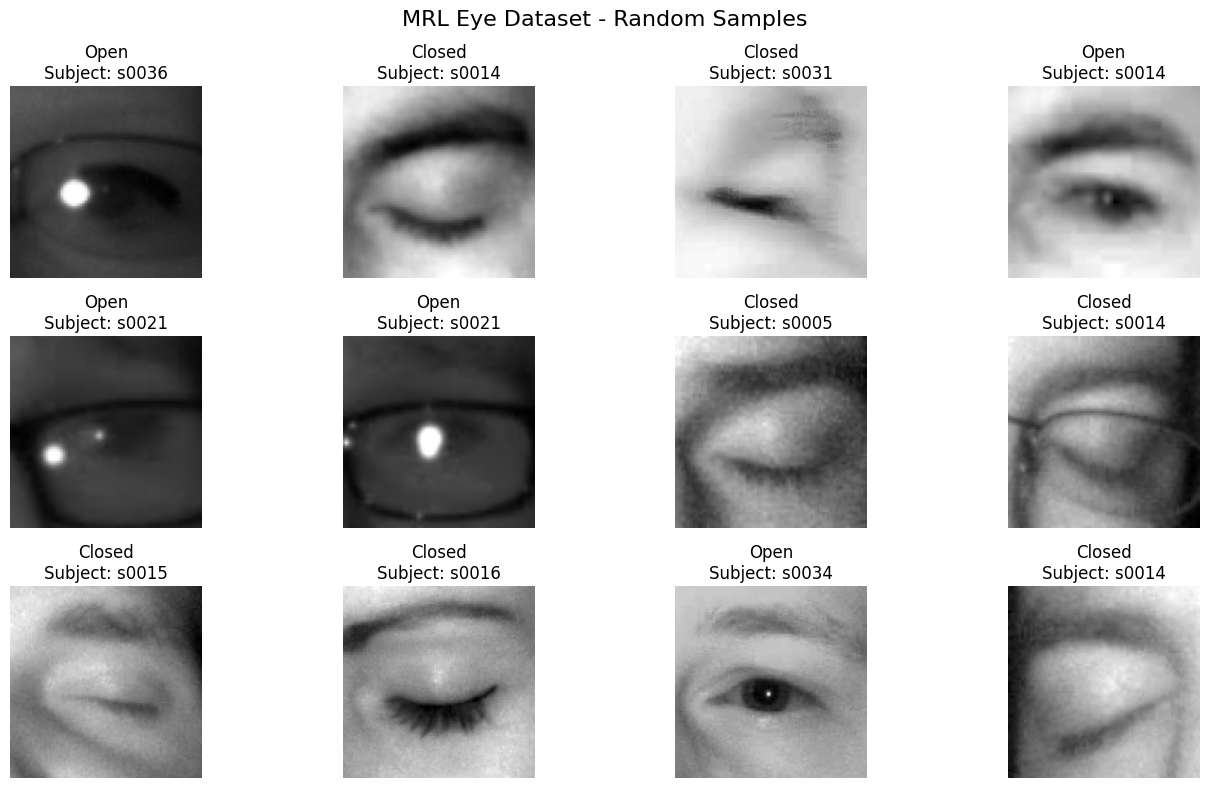

In [6]:

# ==========================================
# CELL 6: VISUALIZE SAMPLE IMAGES
# ==========================================

plt.figure(figsize=(14, 8))

sample_df = df.sample(
    n=12,
    random_state=SEED
).reset_index(drop=True)

for i, row in sample_df.iterrows():

    image = Image.open(
        row["image_path"]
    ).convert("L")

    plt.subplot(3, 4, i + 1)

    plt.imshow(image, cmap="gray")

    plt.title(
        f'{row["class_name"]}\n'
        f'Subject: {row["subject_id"]}'
    )

    plt.axis("off")

plt.suptitle(
    "MRL Eye Dataset - Random Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()


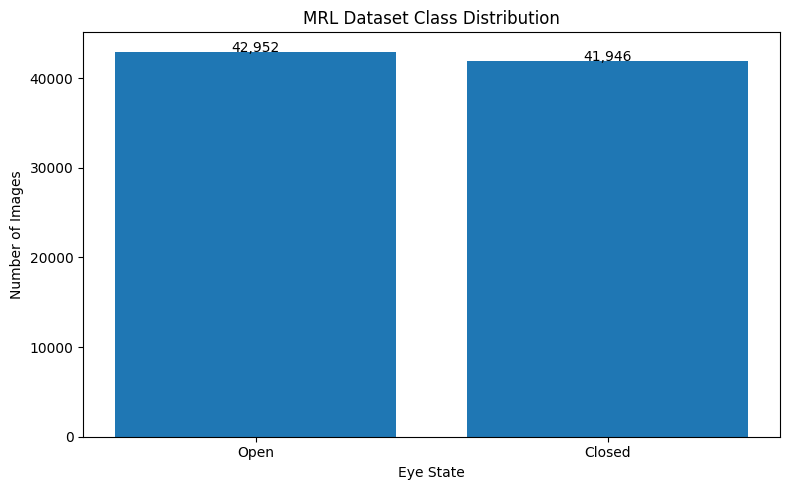

Class Percentages:
class_name
Open      50.59
Closed    49.41
Name: count, dtype: float64


In [7]:

# ==========================================
# CELL 7: CLASS DISTRIBUTION
# ==========================================

class_counts = df["class_name"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("MRL Dataset Class Distribution")
plt.xlabel("Eye State")
plt.ylabel("Number of Images")

for i, value in enumerate(class_counts.values):
    plt.text(i, value, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

print("Class Percentages:")

print(
    (class_counts / len(df) * 100).round(2)
)


In [8]:

# ==========================================
# CELL 8: SUBJECT-WISE TRAIN / VALIDATION SPLIT
# ==========================================

from sklearn.model_selection import GroupShuffleSplit

best_score = float("inf")
best_split = None

for seed in range(300):

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=seed
    )

    train_idx, val_idx = next(
        splitter.split(
            df,
            groups=df["subject_id"]
        )
    )

    train_df_candidate = df.iloc[train_idx]
    val_df_candidate = df.iloc[val_idx]

    val_ratio = len(val_df_candidate) / len(df)

    train_classes = (
        train_df_candidate["label"]
        .value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
    )

    val_classes = (
        val_df_candidate["label"]
        .value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
    )

    score = (
        abs(val_ratio - 0.20)
        + np.abs(
            train_classes.values - val_classes.values
        ).mean()
    )

    if score < best_score:
        best_score = score
        best_split = (train_idx, val_idx)

train_idx, val_idx = best_split

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

print("=" * 45)
print("TRAIN / VALIDATION SPLIT")
print("=" * 45)

print("Total Images:", len(df))
print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))

print("\nTraining Percentage:",
      round(len(train_df) / len(df) * 100, 2), "%")

print("Validation Percentage:",
      round(len(val_df) / len(df) * 100, 2), "%")

print("\nTraining Subjects:",
      train_df["subject_id"].nunique())

print("Validation Subjects:",
      val_df["subject_id"].nunique())

# Verify no subject leakage
train_subjects = set(train_df["subject_id"])
val_subjects = set(val_df["subject_id"])

overlap = train_subjects.intersection(val_subjects)

print("\nSubject Overlap:", len(overlap))
print("No Data Leakage:", len(overlap) == 0)

print("\nTraining Class Distribution:")
print(train_df["class_name"].value_counts())

print("\nValidation Class Distribution:")
print(val_df["class_name"].value_counts())

assert len(overlap) == 0, "Data Leakage Detected!"


TRAIN / VALIDATION SPLIT
Total Images: 84898
Training Images: 67597
Validation Images: 17301

Training Percentage: 79.62 %
Validation Percentage: 20.38 %

Training Subjects: 29
Validation Subjects: 8

Subject Overlap: 0
No Data Leakage: True

Training Class Distribution:
class_name
Open      34189
Closed    33408
Name: count, dtype: int64

Validation Class Distribution:
class_name
Open      8763
Closed    8538
Name: count, dtype: int64


In [9]:

# ==========================================
# CELL 9: IMAGE PREPROCESSING
# ==========================================

IMG_SIZE = 64
BATCH_SIZE = 32

def preprocess_image(image_path, label):

    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.float32)

    return image, label


def create_dataset(dataframe, training=False):

    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(
    train_df,
    training=True
)

val_ds = create_dataset(
    val_df,
    training=False
)

print("Preprocessing completed!")
print("Image Size:", IMG_SIZE, "x", IMG_SIZE)
print("Channels: 1 (Grayscale)")
print("Batch Size:", BATCH_SIZE)


Preprocessing completed!
Image Size: 64 x 64
Channels: 1 (Grayscale)
Batch Size: 32


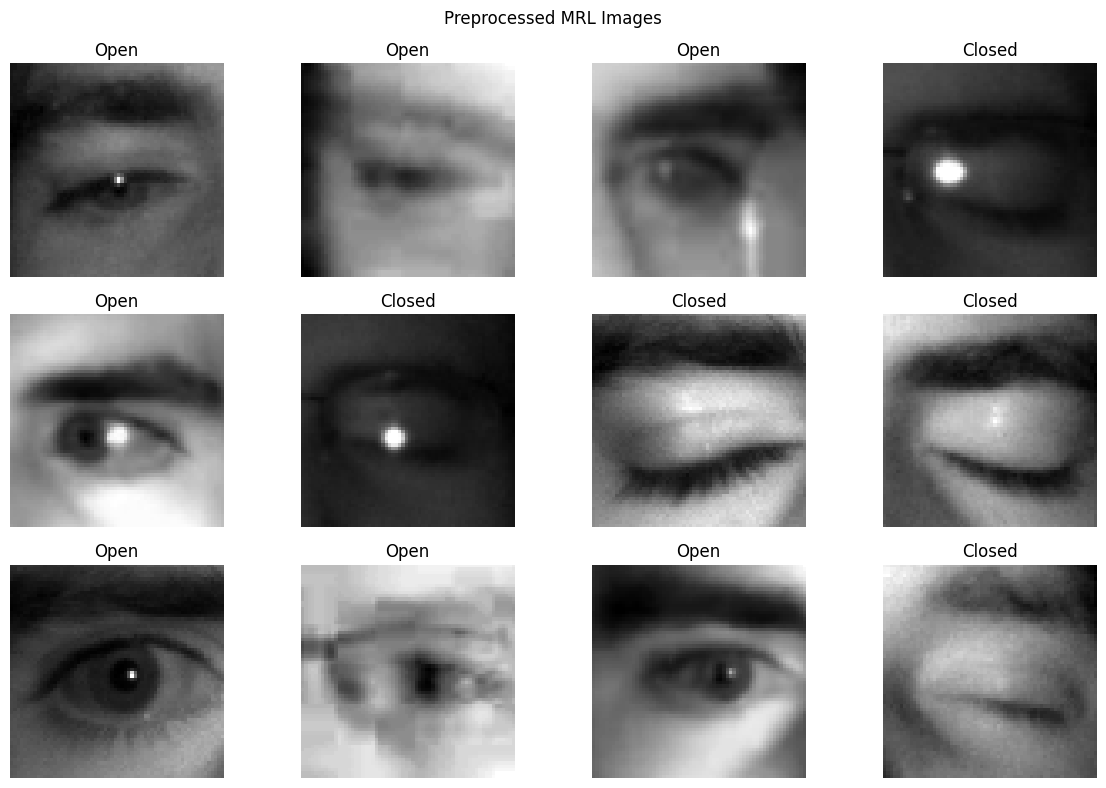

Batch Shape: (32, 64, 64, 1)
Label Shape: (32,)
Pixel Range: 0.0 to 1.0


In [10]:

# ==========================================
# CELL 10: PREVIEW PREPROCESSED IMAGES
# ==========================================

images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        images[i].numpy().squeeze(),
        cmap="gray"
    )

    label = int(labels[i].numpy())

    plt.title(
        "Open" if label == 1 else "Closed"
    )

    plt.axis("off")

plt.suptitle("Preprocessed MRL Images")
plt.tight_layout()
plt.show()

print("Batch Shape:", images.shape)
print("Label Shape:", labels.shape)
print("Pixel Range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))


In [11]:

# ==========================================
# CELL 11: BUILD CNN MODEL
# ==========================================

from tensorflow.keras import layers, models

cnn_model = models.Sequential([

    layers.Input(shape=(64, 64, 1)),

    # Block 1
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),

    layers.Dropout(0.4),

    layers.Dense(1, activation="sigmoid")
])

print("CNN Model Created Successfully!")


CNN Model Created Successfully!


In [12]:

# ==========================================
# CELL 12: MODEL SUMMARY AND PARAMETERS
# ==========================================

cnn_model.summary()

total_params = cnn_model.count_params()

trainable_params = sum(
    np.prod(v.shape)
    for v in cnn_model.trainable_weights
)

non_trainable_params = sum(
    np.prod(v.shape)
    for v in cnn_model.non_trainable_weights
)

print("\nMODEL PARAMETERS")
print("-" * 35)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Non-Trainable Parameters:", non_trainable_params)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)


MODEL PARAMETERS
-----------------------------------
Total Parameters: 100993
Trainable Parameters: 100993
Non-Trainable Parameters: 0


In [13]:

# ==========================================
# CELL 13: COMPILE MODEL
# ==========================================

cnn_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("CNN Model Compiled Successfully!")

print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Loss: Binary Crossentropy")
print("Execution: CPU")


CNN Model Compiled Successfully!
Optimizer: Adam
Learning Rate: 0.001
Loss: Binary Crossentropy
Execution: CPU


In [14]:

# ==========================================
# CELL 14: TRAIN CNN MODEL
# ==========================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

RESULTS_DIR = "/content/SmartCap_CNN/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=os.path.join(
            RESULTS_DIR,
            "best_mrl_cnn.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

EPOCHS = 20

print("Starting CNN Training on CPU...")

history = cnn_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1
)

print("\nTraining Completed!")


Starting CNN Training on CPU...
Epoch 1/20
2113/2113 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.6007 - loss: 0.6286 - precision: 0.6081 - recall: 0.6792
Epoch 1: val_loss improved from None to 0.47652, saving model to /content/SmartCap_CNN/results/best_mrl_cnn.keras

Epoch 1: finished saving model to /content/SmartCap_CNN/results/best_mrl_cnn.keras
2113/2113 ━━━━━━━━━━━━━━━━━━━━ 716s 337ms/step - accuracy: 0.6880 - loss: 0.5476 - precision: 0.6972 - recall: 0.6774 - val_accuracy: 0.7893 - val_loss: 0.4765 - val_precision: 0.8033 - val_recall: 0.7733 - learning_rate: 0.0010
Epoch 2/20
2113/2113 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.8774 - loss: 0.3120 - precision: 0.8878 - recall: 0.8722
Epoch 2: val_loss improved from 0.47652 to 0.21251, saving model to /content/SmartCap_CNN/results/best_mrl_cnn.keras

Epoch 2: finished saving model to /content/SmartCap_CNN/results/best_mrl_cnn.keras
2113/2113 ━━━━━━━━━━━━━━━━━━━━ 683s 323ms/step - accuracy: 0.8976 - loss: 0.2684 - pre

KeyboardInterrupt: 

In [15]:

# Load the best saved MRL CNN model

BEST_MODEL_PATH = (
    "/content/SmartCap_CNN/results/best_mrl_cnn.keras"
)

cnn_model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

print("Best MRL CNN model loaded successfully!")
print("Best saved model is ready for evaluation.")


Best MRL CNN model loaded successfully!
Best saved model is ready for evaluation.


In [16]:

# ==========================================
# CELL 18: MRL MODEL EVALUATION
# ==========================================

evaluation_results = cnn_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)

print("\n========== MRL CNN EVALUATION ==========")

for metric, value in evaluation_results.items():
    print(f"{metric}: {value:.4f}")



541/541 ━━━━━━━━━━━━━━━━━━━━ 55s 99ms/step - accuracy: 0.9415 - loss: 0.1479 - precision: 0.9485 - recall: 0.9353

========== MRL CNN EVALUATION ==========
accuracy: 0.9415
loss: 0.1479
precision: 0.9485
recall: 0.9353


In [17]:

# ==========================================
# CELL 19: CLASSIFICATION REPORT
# ==========================================

y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
]).astype(int)

y_prob = cnn_model.predict(val_ds, verbose=1).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print("\nMRL CNN CLASSIFICATION REPORT\n")

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Closed", "Open"],
    digits=4
)

print(report)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

print("Overall Accuracy:", round(accuracy, 4))
print("Overall Precision:", round(precision, 4))
print("Overall Recall:", round(recall, 4))
print("Overall F1-Score:", round(f1, 4))


541/541 ━━━━━━━━━━━━━━━━━━━━ 72s 132ms/step

MRL CNN CLASSIFICATION REPORT

              precision    recall  f1-score   support

      Closed     0.9345    0.9479    0.9412      8538
        Open     0.9485    0.9353    0.9419      8763

    accuracy                         0.9415     17301
   macro avg     0.9415    0.9416    0.9415     17301
weighted avg     0.9416    0.9415    0.9415     17301

Overall Accuracy: 0.9415
Overall Precision: 0.9485
Overall Recall: 0.9353
Overall F1-Score: 0.9419


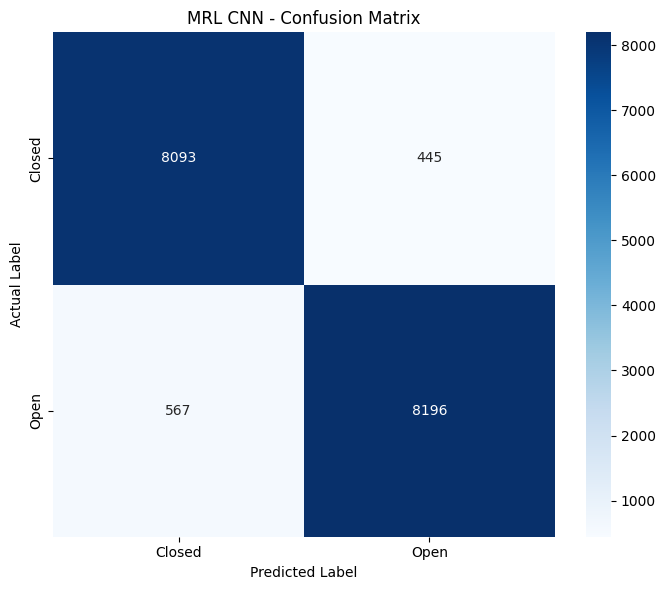

Confusion Matrix:
[[8093  445]
 [ 567 8196]]


In [18]:

# ==========================================
# CELL 20: CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Closed", "Open"],
    yticklabels=["Closed", "Open"]
)

plt.title("MRL CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "confusion_matrix.png"),
    dpi=300
)

plt.show()

print("Confusion Matrix:")
print(cm)


In [19]:

# ==========================================
# CELL 21: SAVE MRL EXPERIMENT RESULTS
# ==========================================

mrl_results = {
    "Dataset": "MRL Only",
    "Model": "CNN",
    "Image_Size": "64x64",
    "Color_Mode": "Grayscale",
    "Train_Images": len(train_df),
    "Validation_Images": len(val_df),
    "Train_Percentage": round(
        len(train_df) / len(df) * 100, 2
    ),
    "Validation_Percentage": round(
        len(val_df) / len(df) * 100, 2
    ),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1,
    "Validation_Loss": evaluation_results["loss"],
    "Total_Parameters": cnn_model.count_params()
}

mrl_results_df = pd.DataFrame([mrl_results])

mrl_results_df.to_csv(
    os.path.join(RESULTS_DIR, "mrl_results.csv"),
    index=False
)

print(mrl_results_df.T)

print("\nMRL Results Saved Successfully!")


                               0
Dataset                 MRL Only
Model                        CNN
Image_Size                 64x64
Color_Mode             Grayscale
Train_Images               67597
Validation_Images          17301
Train_Percentage           79.62
Validation_Percentage      20.38
Accuracy                0.941506
Precision               0.948501
Recall                  0.935296
F1_Score                0.941852
Validation_Loss         0.147857
Total_Parameters          100993

MRL Results Saved Successfully!


In [20]:

# ==========================================
# CELL 22: SAVE TRAINING HISTORY
# ==========================================

history_df = pd.DataFrame(history.history)

history_df.index.name = "Epoch"

history_df.to_csv(
    os.path.join(RESULTS_DIR, "mrl_training_history.csv")
)

print("Training history saved successfully!")

print(history_df.tail())


NameError: name 'history' is not defined

In [21]:
import os
import pandas as pd

RESULTS_DIR = "/content/SmartCap_CNN/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Saved experiment files:")
for file in os.listdir(RESULTS_DIR):
    print(file)

Saved experiment files:
best_mrl_cnn.keras
mrl_results.csv
confusion_matrix.png


In [22]:
import os

RESULTS_DIR = "/content/SmartCap_CNN/results"

print("Available files:")
for root, dirs, files in os.walk(RESULTS_DIR):
    for file in files:
        print(os.path.join(root, file))

Available files:
/content/SmartCap_CNN/results/best_mrl_cnn.keras
/content/SmartCap_CNN/results/mrl_results.csv
/content/SmartCap_CNN/results/confusion_matrix.png


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history_path = "/content/SmartCap_CNN/results/mrl_training_history.csv"

history_df = pd.read_csv(history_path)

plt.figure(figsize=(9, 5))
plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.title("MRL CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("/content/SmartCap_CNN/results/accuracy.png", dpi=300)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.title("MRL CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig("/content/SmartCap_CNN/results/loss.png", dpi=300)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/SmartCap_CNN/results/mrl_training_history.csv'

In [24]:
import os

RESULTS_DIR = "/content/SmartCap_CNN/results"

print("Results folder exists:", os.path.exists(RESULTS_DIR))

if os.path.exists(RESULTS_DIR):
    for file in os.listdir(RESULTS_DIR):
        print(file)

Results folder exists: True
best_mrl_cnn.keras
mrl_results.csv
confusion_matrix.png


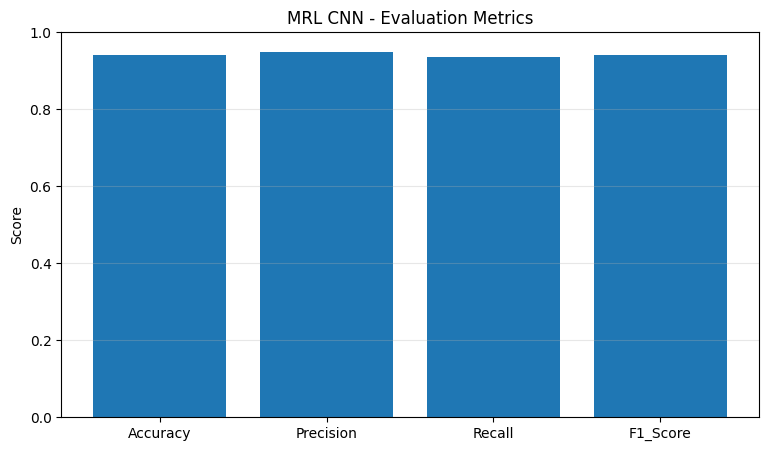

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

results_path = "/content/SmartCap_CNN/results/mrl_results.csv"

if os.path.exists(results_path):
    results = pd.read_csv(results_path)

    metrics = ["Accuracy", "Precision", "Recall", "F1_Score"]

    values = results.iloc[0][metrics]

    plt.figure(figsize=(9, 5))
    plt.bar(metrics, values)
    plt.ylim(0, 1)
    plt.title("MRL CNN - Evaluation Metrics")
    plt.ylabel("Score")
    plt.grid(axis="y", alpha=0.3)
    plt.savefig("/content/SmartCap_CNN/results/mrl_evaluation_metrics.png", dpi=300)
    plt.show()
else:
    print("mrl_results.csv is not available.")

MRL CNN Results:


,Dataset,Model,Image_Size,Color_Mode,Train_Images,Validation_Images,Train_Percentage,Validation_Percentage,Accuracy,Precision,Recall,F1_Score,Validation_Loss,Total_Parameters
0,MRL Only,CNN,64x64,Grayscale,67597,17301,79.62,20.38,0.941506,0.948501,0.935296,0.941852,0.147857,100993


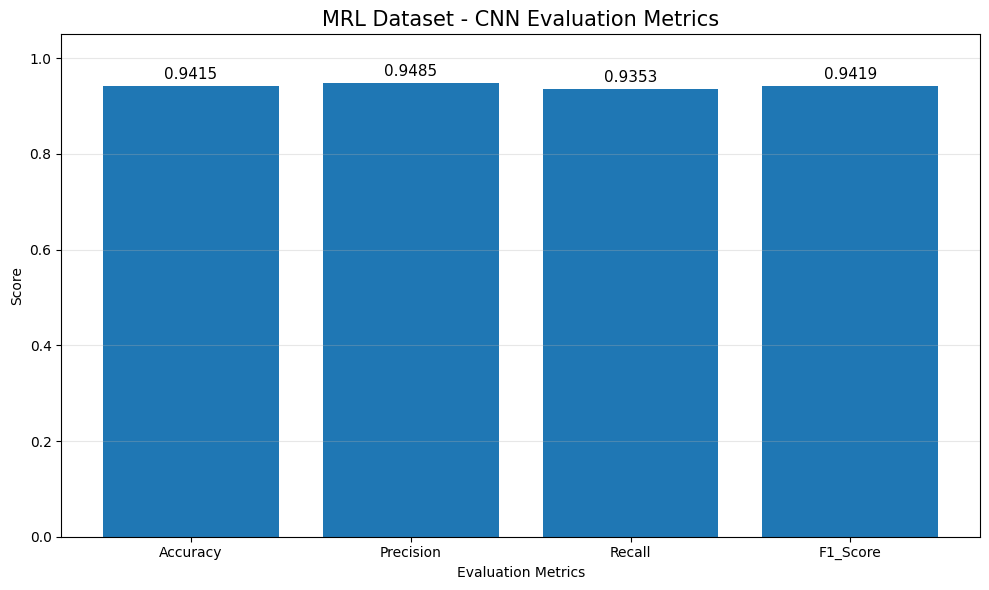

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import os

RESULTS_DIR = "/content/SmartCap_CNN/results"
results_path = os.path.join(RESULTS_DIR, "mrl_results.csv")

results = pd.read_csv(results_path)

print("MRL CNN Results:")
display(results)

metrics = ["Accuracy", "Precision", "Recall", "F1_Score"]
values = results.loc[0, metrics].astype(float)

plt.figure(figsize=(10, 6))

bars = plt.bar(metrics, values)

plt.title("MRL Dataset - CNN Evaluation Metrics", fontsize=15)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.4f}",
        ha="center",
        fontsize=11
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "mrl_evaluation_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

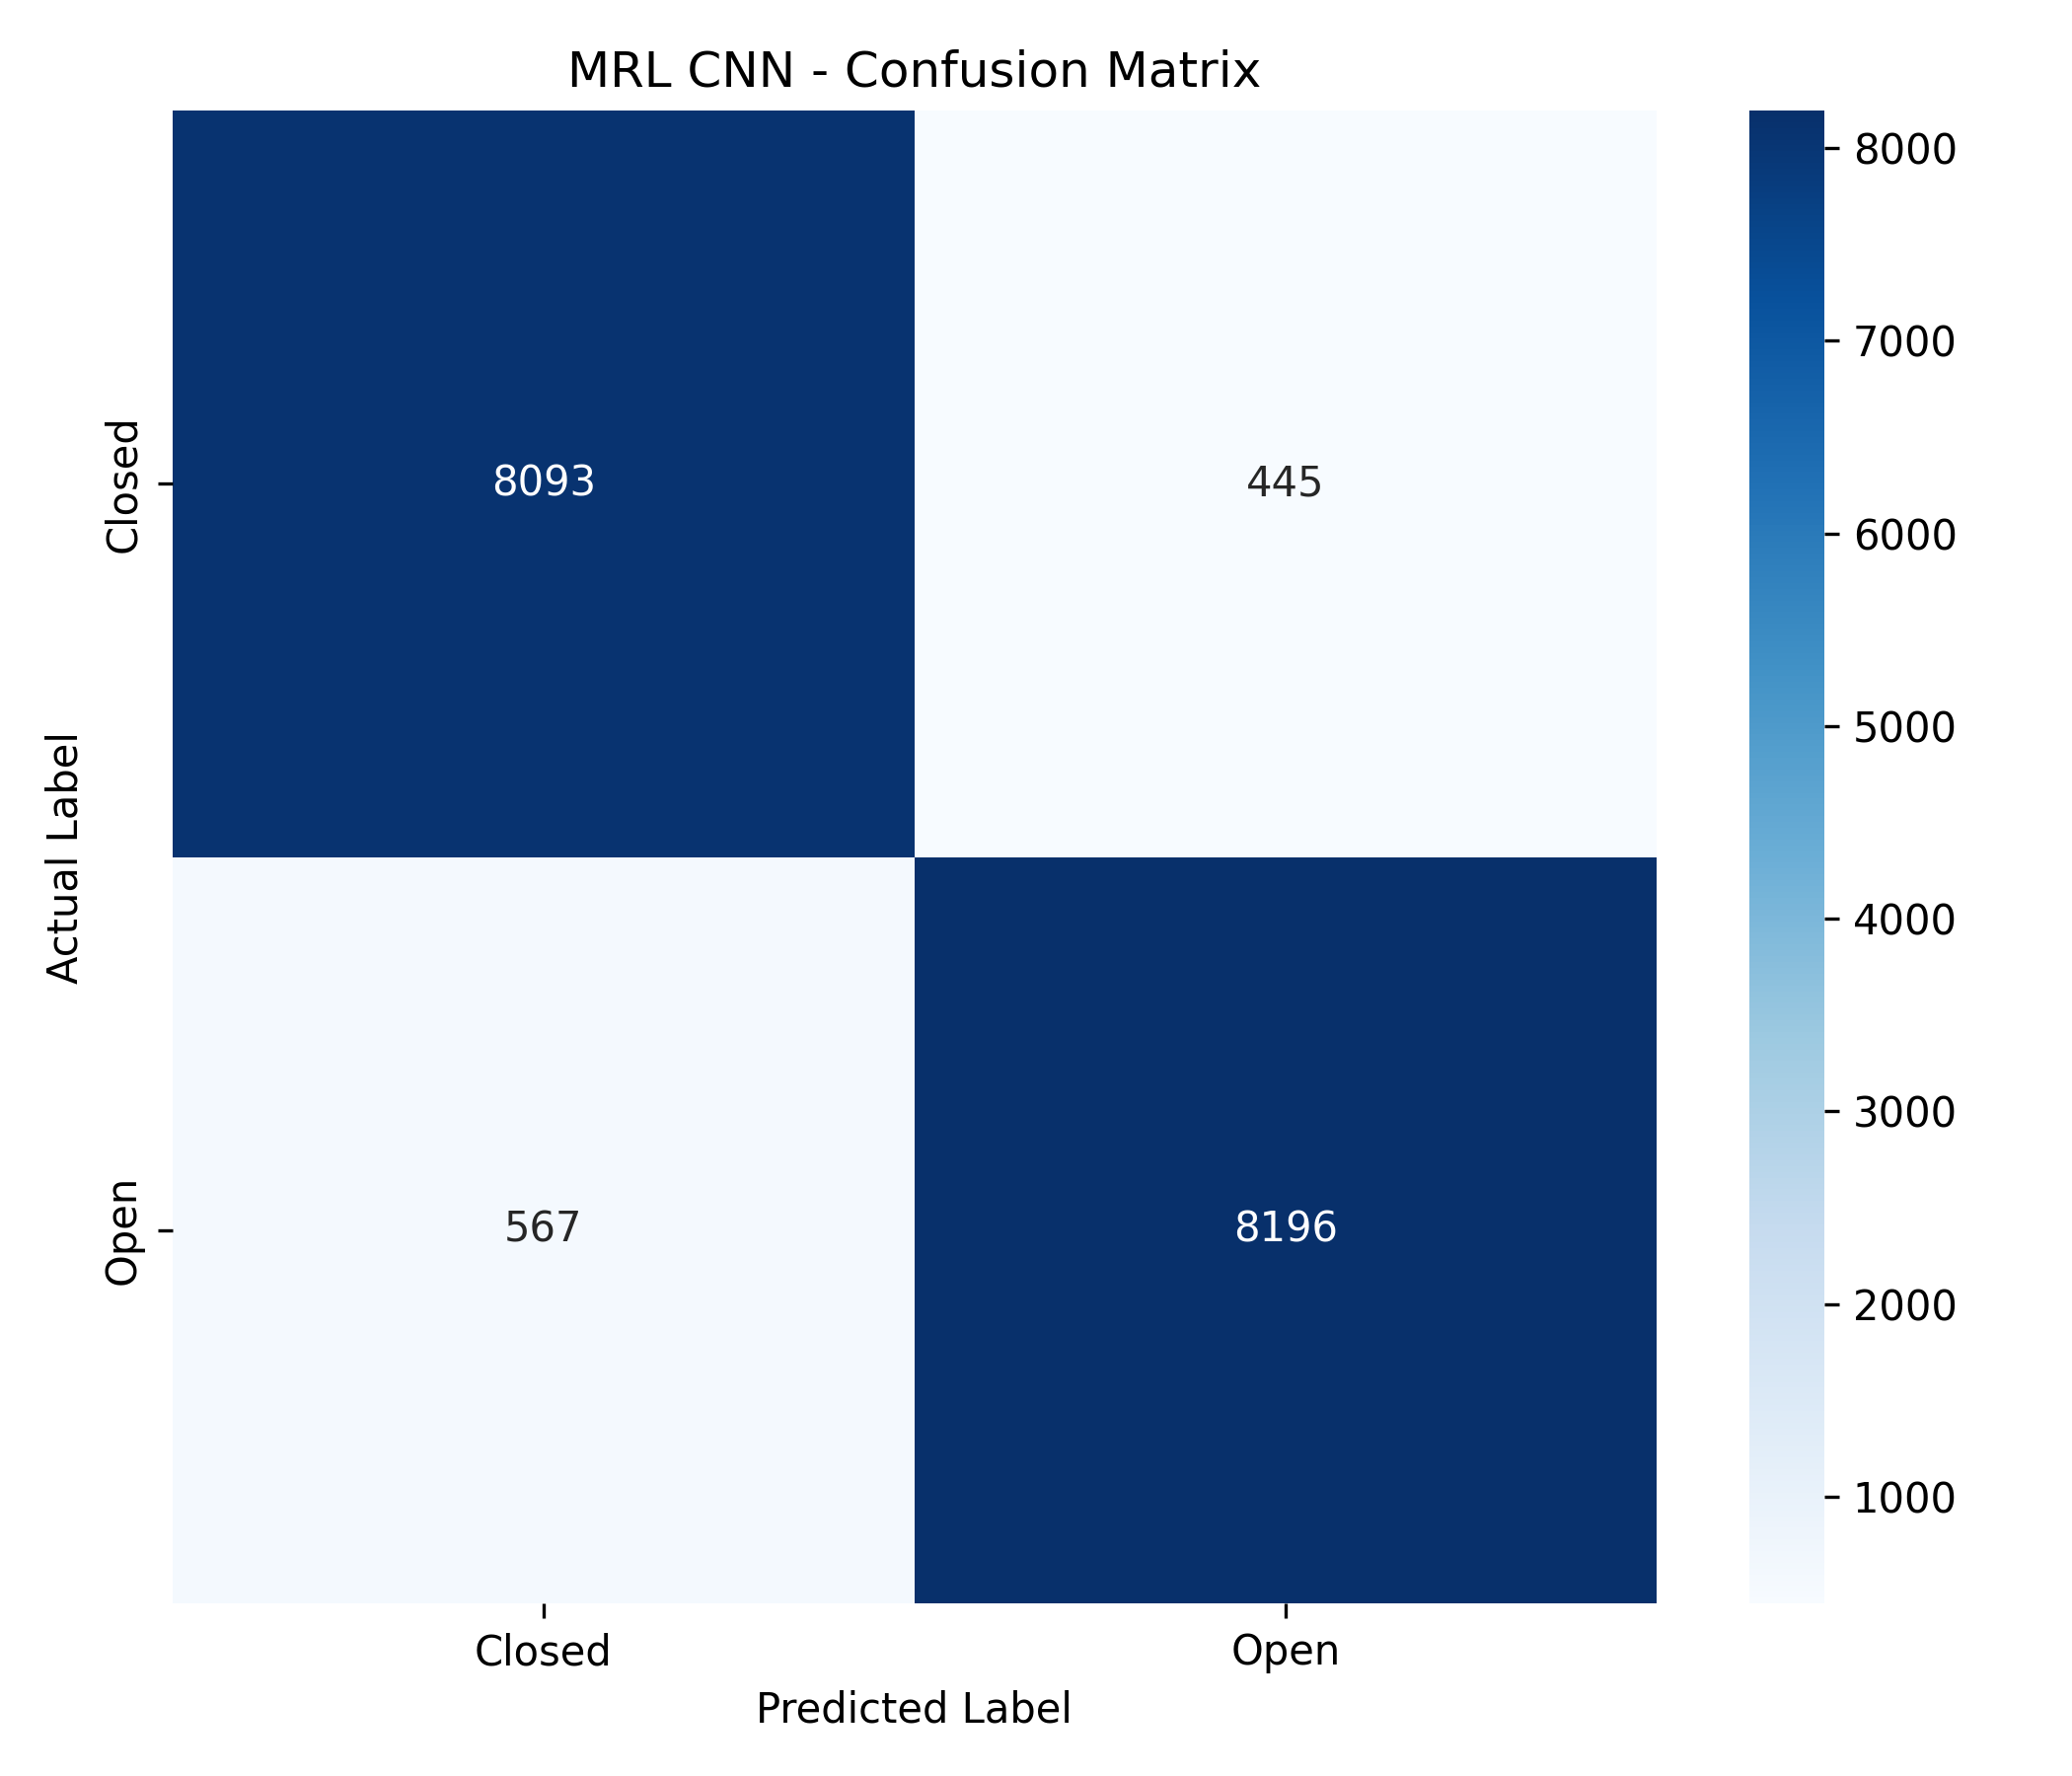

In [27]:
from IPython.display import display, Image

display(
    Image(
        filename="/content/SmartCap_CNN/results/confusion_matrix.png",
        width=700
    )
)

In [28]:
import zipfile
import os

RESULTS_DIR = "/content/SmartCap_CNN/results"
ZIP_PATH = "/content/MRL_CNN_Results.zip"

files_to_save = [
    "best_mrl_cnn.keras",
    "mrl_results.csv",
    "confusion_matrix.png",
    "mrl_evaluation_metrics.png"
]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_save:
        filepath = os.path.join(RESULTS_DIR, filename)
        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)

print("Results package created:", ZIP_PATH)

from google.colab import files
files.download(ZIP_PATH)

Results package created: /content/MRL_CNN_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import pandas as pd

history_data = {
    "Epoch": [1, 2, 3, 4, 5, 6, 7],

    "accuracy": [
        0.6880, 0.8976, 0.9465, 0.9586,
        0.9657, 0.9713, 0.9770
    ],

    "val_accuracy": [
        0.7893, 0.9204, 0.9149, 0.9415,
        0.9185, 0.9099, 0.9490
    ],

    "loss": [
        0.5476, 0.2684, 0.1457, 0.1135,
        0.0984, 0.0830, 0.0671
    ],

    "val_loss": [
        0.4765, 0.2125, 0.1945, 0.1479,
        0.2195, 0.2364, 0.1650
    ]
}

history_df = pd.DataFrame(history_data)
display(history_df)

,Epoch,accuracy,val_accuracy,loss,val_loss
0,1,0.6880,0.7893,0.5476,0.4765
1,2,0.8976,0.9204,0.2684,0.2125
2,3,0.9465,0.9149,0.1457,0.1945
3,4,0.9586,0.9415,0.1135,0.1479
4,5,0.9657,0.9185,0.0984,0.2195
5,6,0.9713,0.9099,0.0830,0.2364
6,7,0.9770,0.9490,0.0671,0.1650


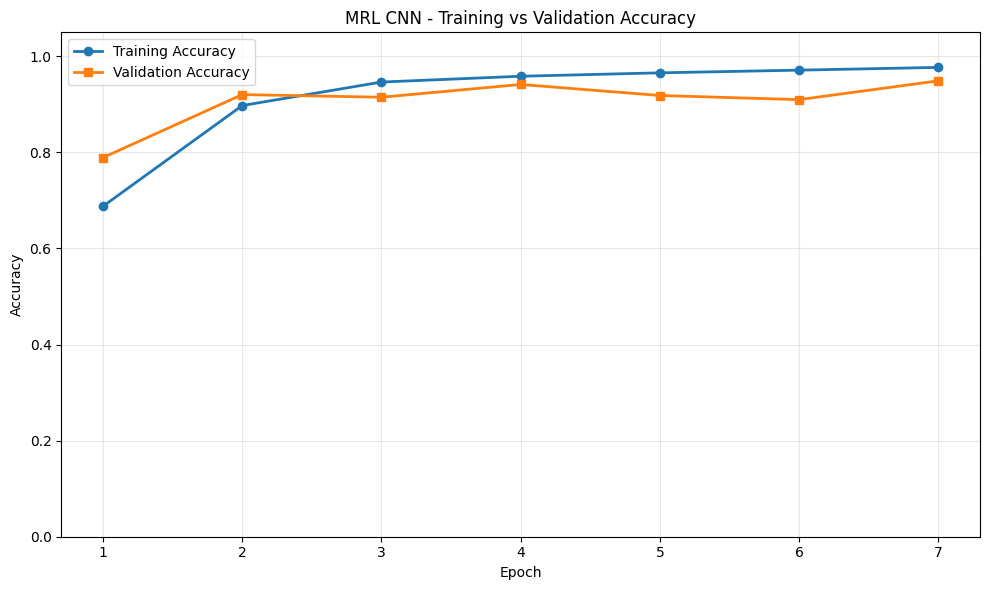

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["Epoch"],
    history_df["accuracy"],
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    history_df["Epoch"],
    history_df["val_accuracy"],
    marker="s",
    linewidth=2,
    label="Validation Accuracy"
)

plt.title("MRL CNN - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(history_df["Epoch"])
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/SmartCap_CNN/results/training_validation_accuracy.png",
    dpi=300
)

plt.show()

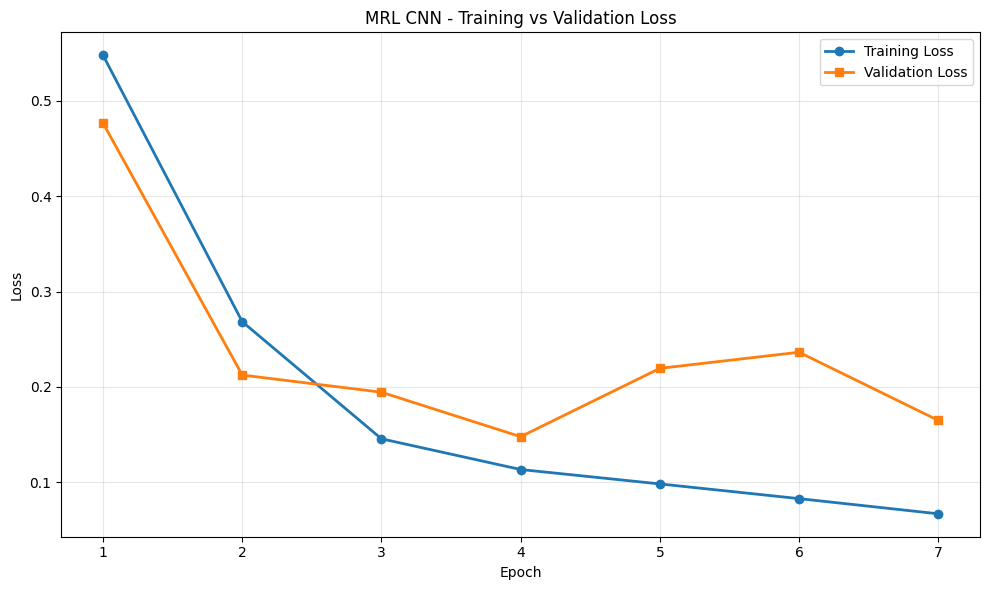

In [31]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["Epoch"],
    history_df["loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    history_df["Epoch"],
    history_df["val_loss"],
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

plt.title("MRL CNN - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(history_df["Epoch"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/SmartCap_CNN/results/training_validation_loss.png",
    dpi=300
)

plt.show()

In [32]:
history_df.to_csv(
    "/content/SmartCap_CNN/results/mrl_training_history.csv",
    index=False
)

print("Training history saved successfully!")

Training history saved successfully!


In [33]:
!apt-get update -qq
!apt-get install unrar -y -qq


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [34]:
from google.colab import files

uploaded = files.upload()

Saving data_raw.rar to data_raw (1).rar


In [35]:
import os
import subprocess

BASE_DIR = "/content/SmartCap_CNN"
RAR_DIR = os.path.join(BASE_DIR, "smartcap_dataset")

os.makedirs(RAR_DIR, exist_ok=True)

rar_file = next(
    filename for filename in uploaded.keys()
    if filename.lower().endswith(".rar")
)

rar_path = os.path.join("/content", rar_file)

result = subprocess.run(
    ["unrar", "x", "-o+", rar_path, RAR_DIR + "/"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("RAR extraction failed")

print("Extraction completed successfully!")


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/data_raw (1).rar

Creating    /content/SmartCap_CNN/smartcap_dataset/data_raw           OK
Creating    /content/SmartCap_CNN/smartcap_dataset/data_raw/P01       OK
Creating    /content/SmartCap_CNN/smartcap_dataset/data_raw/P01/s01   OK
Extracting  /content/SmartCap_CNN/smartcap_dataset/data_raw/P01/s01/log.csv       0%  OK 
Extracting  /content/SmartCap_CNN/smartcap_dataset/data_raw/P01/s01/meta.json       0%  OK 
Creating    /content/SmartCap_CNN/smartcap_dataset/data_raw/P01/test01  OK
Creating    /content/SmartCap_CNN/smartcap_dataset/data_raw/P01/test01/closed  OK
Extracting  /content/SmartCap_CNN/smartcap_dataset/data_raw/P01/test01/closed/P01_test01_20261110_131154_165549_L.png       0%  OK 
Extracting  /content/SmartCap_CNN/smartcap_dataset/data_raw/P01/test01/closed/P01_test01_20261110_131154_165549_R.png       0%  OK 
Extracting  /content/SmartCap_

In [36]:
for root, dirs, files_list in os.walk(RAR_DIR):
    level = root.replace(RAR_DIR, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for filename in files_list[:5]:
        print("  " * (level + 1) + filename)

smartcap_dataset/
  data_raw/
    P01/
      test01/
        log.csv
        meta.json
      s01/
        log.csv
        meta.json
    P02/
      test02/
        log.csv
        meta.json
      test01/
        log.csv
        meta.json


In [37]:
import os
import pandas as pd

DATA_DIR = "/content/SmartCap_CNN/smartcap_dataset/data_raw"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

session_summary = []

for person in sorted(os.listdir(DATA_DIR)):
    person_path = os.path.join(DATA_DIR, person)

    if not os.path.isdir(person_path):
        continue

    for session in sorted(os.listdir(person_path)):
        session_path = os.path.join(person_path, session)

        if not os.path.isdir(session_path):
            continue

        images = []

        for root, dirs, files_list in os.walk(session_path):
            for file in files_list:
                if file.lower().endswith(image_extensions):
                    images.append(os.path.join(root, file))

        session_summary.append({
            "Person": person,
            "Session": session,
            "Images": len(images),
            "Has_Log": os.path.exists(
                os.path.join(session_path, "log.csv")
            ),
            "Has_Meta": os.path.exists(
                os.path.join(session_path, "meta.json")
            )
        })

summary_df = pd.DataFrame(session_summary)

display(summary_df)

print("Total Sessions:", len(summary_df))
print("Total Images:", summary_df["Images"].sum())

,Person,Session,Images,Has_Log,Has_Meta
0,P01,s01,0,True,True
1,P01,test01,46,True,True
2,P02,test01,280,True,True
3,P02,test02,387,True,True


Total Sessions: 4
Total Images: 713


In [38]:
import os
import pandas as pd

DATA_DIR = "/content/SmartCap_CNN/smartcap_dataset/data_raw"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

session_summary = []

for person in sorted(os.listdir(DATA_DIR)):
    person_path = os.path.join(DATA_DIR, person)

    if not os.path.isdir(person_path):
        continue

    for session in sorted(os.listdir(person_path)):
        session_path = os.path.join(person_path, session)

        if not os.path.isdir(session_path):
            continue

        images = []

        for root, dirs, files_list in os.walk(session_path):
            for file in files_list:
                if file.lower().endswith(image_extensions):
                    images.append(os.path.join(root, file))

        session_summary.append({
            "Person": person,
            "Session": session,
            "Images": len(images),
            "Has_Log": os.path.exists(
                os.path.join(session_path, "log.csv")
            ),
            "Has_Meta": os.path.exists(
                os.path.join(session_path, "meta.json")
            )
        })

summary_df = pd.DataFrame(session_summary)

display(summary_df)

print("Total Sessions:", len(summary_df))
print("Total Images:", summary_df["Images"].sum())

,Person,Session,Images,Has_Log,Has_Meta
0,P01,s01,0,True,True
1,P01,test01,46,True,True
2,P02,test01,280,True,True
3,P02,test02,387,True,True


Total Sessions: 4
Total Images: 713


In [39]:
import os
import pandas as pd

for person in sorted(os.listdir(DATA_DIR)):
    person_path = os.path.join(DATA_DIR, person)

    if not os.path.isdir(person_path):
        continue

    for session in sorted(os.listdir(person_path)):
        session_path = os.path.join(person_path, session)
        log_path = os.path.join(session_path, "log.csv")

        if os.path.isfile(log_path):
            print("\n" + "=" * 60)
            print(f"PERSON: {person} | SESSION: {session}")

            try:
                log_df = pd.read_csv(log_path)

                print("Columns:", log_df.columns.tolist())
                print("Rows:", len(log_df))
                display(log_df.head(5))

            except Exception as e:
                print("Error reading log:", e)


PERSON: P01 | SESSION: s01
Columns: ['file', 't_wall', 'state', 'eye', 'ear']
Rows: 0


,file,t_wall,state,eye,ear



PERSON: P01 | SESSION: test01
Error reading log: Error tokenizing data. C error: Expected 8 fields in line 91, saw 9


PERSON: P02 | SESSION: test01
Columns: ['timestamp', 'frame_number', 'selected_label', 'ear_estimated_state', 'left_ear', 'right_ear', 'average_ear', 'left_image', 'right_image']
Rows: 140


,timestamp,frame_number,selected_label,ear_estimated_state,left_ear,right_ear,average_ear,left_image,right_image
0,2026-11-11T17:39:29.031550,195,open,OPEN,0.392411,0.422688,0.407550,P02_test01_20261111_173929_009595_L.png,P02_test01_20261111_173929_009595_R.png
1,2026-11-11T17:39:29.302477,199,open,OPEN,0.478887,0.573688,0.526287,P02_test01_20261111_173929_286424_L.png,P02_test01_20261111_173929_286424_R.png
2,2026-11-11T17:39:29.640072,203,open,OPEN,0.391415,0.494436,0.442925,P02_test01_20261111_173929_640072_L.png,P02_test01_20261111_173929_640072_R.png
3,2026-11-11T17:39:29.861304,205,open,OPEN,0.422700,0.532017,0.477358,P02_test01_20261111_173929_846135_L.png,P02_test01_20261111_173929_846135_R.png
4,2026-11-11T17:39:30.334606,212,open,OPEN,0.343757,0.384053,0.363905,P02_test01_20261111_173930_329835_L.png,P02_test01_20261111_173930_329835_R.png



PERSON: P02 | SESSION: test02
Columns: ['timestamp', 'frame_number', 'selected_label', 'ear_estimated_state', 'left_ear', 'right_ear', 'average_ear', 'left_image', 'right_image']
Rows: 217


,timestamp,frame_number,selected_label,ear_estimated_state,left_ear,right_ear,average_ear,left_image,right_image
0,2026-11-11T17:27:40.814155,150,open,OPEN,0.377274,0.382343,0.379808,P02_test02_20261111_172740_789463_L.png,P02_test02_20261111_172740_789463_R.png
1,2026-11-11T17:27:41.039552,153,open,CLOSED,0.186465,0.169133,0.177799,P02_test02_20261111_172741_023734_L.png,P02_test02_20261111_172741_023734_R.png
2,2026-11-11T17:27:41.289377,156,open,OPEN,0.242225,0.225366,0.233796,P02_test02_20261111_172741_273418_L.png,P02_test02_20261111_172741_273418_R.png
3,2026-11-11T17:27:41.528738,159,open,OPEN,0.385056,0.344446,0.364751,P02_test02_20261111_172741_514515_L.png,P02_test02_20261111_172741_514515_R.png
4,2026-11-11T17:27:41.757350,162,open,OPEN,0.249230,0.209031,0.229131,P02_test02_20261111_172741_740251_L.png,P02_test02_20261111_172741_740251_R.png


In [40]:
import os
import json

for person in sorted(os.listdir(DATA_DIR)):
    person_path = os.path.join(DATA_DIR, person)

    if not os.path.isdir(person_path):
        continue

    for session in sorted(os.listdir(person_path)):
        session_path = os.path.join(person_path, session)
        meta_path = os.path.join(session_path, "meta.json")

        if os.path.isfile(meta_path):
            print(f"\n{person}/{session}")

            with open(meta_path, "r", encoding="utf-8") as f:
                metadata = json.load(f)

            print(json.dumps(metadata, indent=4, ensure_ascii=False))


P01/s01
{
    "subject": "P01",
    "session": "s01",
    "url": "http://192.168.4.1/stream",
    "lighting": "normal",
    "glasses": 0,
    "placement": "cap",
    "interval": 0.2,
    "skip": 1.5,
    "out": "D:\\SmartCap-driver-monitoring\\edge_ai\\vision\\data_raw",
    "model": "D:\\SmartCap-driver-monitoring\\edge_ai\\vision\\models\\face_landmarker.task",
    "date": "2026-11-10T10:11:25"
}

P01/test01
{
    "subject": "P01",
    "session": "test01",
    "lighting": "normal",
    "glasses": "0",
    "placement": "cap",
    "camera_url": "http://192.168.4.1/stream",
    "camera_rotation": "180_degrees",
    "image_size": "64x64",
    "label_method": "manual_keyboard_selection_with_EAR_check",
    "ear_threshold": 0.2,
    "created_at": "2026-11-10T13:11:25.645037"
}

P02/test01
{
    "subject": "P02",
    "session": "test01",
    "lighting": "normal",
    "glasses": "0",
    "placement": "cap",
    "camera_url": "http://192.168.4.1/stream",
    "camera_rotation": 180,
    "imag

In [41]:
import os
import csv
import pandas as pd
from collections import Counter

DATA_DIR = "/content/SmartCap_CNN/smartcap_dataset/data_raw"

IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp")

for person in sorted(os.listdir(DATA_DIR)):

    person_path = os.path.join(DATA_DIR, person)

    if not os.path.isdir(person_path):
        continue

    for session in sorted(os.listdir(person_path)):

        session_path = os.path.join(person_path, session)

        if not os.path.isdir(session_path):
            continue

        print("\n" + "=" * 65)
        print(f"PERSON: {person} | SESSION: {session}")

        # 1. Collect images
        image_files = []

        for root, dirs, files_list in os.walk(session_path):
            for filename in files_list:
                if filename.lower().endswith(IMAGE_EXTENSIONS):
                    image_files.append(filename)

        image_set = set(image_files)

        print("Total images:", len(image_files))

        # 2. Read CSV
        log_path = os.path.join(session_path, "log.csv")

        if not os.path.exists(log_path):
            print("No log.csv found")
            continue

        try:
            log_df = pd.read_csv(
                log_path,
                engine="python",
                on_bad_lines="warn"
            )

            print("CSV rows:", len(log_df))
            print("Columns:", log_df.columns.tolist())

        except Exception as e:
            print("CSV reading failed:", e)
            continue

        # 3. Detect label columns
        if "selected_label" in log_df.columns:
            label_column = "selected_label"

        elif "state" in log_df.columns:
            label_column = "state"

        else:
            print("No recognized label column")
            continue

        labels = (
            log_df[label_column]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        print("\nLabel distribution:")
        print(labels.value_counts(dropna=False))

        print("Valid Open:", (labels == "open").sum())
        print("Valid Closed:", (labels == "closed").sum())

        # 4. Check referenced image files
        image_columns = [
            col for col in ["file", "left_image", "right_image"]
            if col in log_df.columns
        ]

        for col in image_columns:

            referenced = (
                log_df[col]
                .dropna()
                .astype(str)
                .str.strip()
            )

            missing = [
                filename for filename in referenced
                if filename and filename not in image_set
            ]

            print(f"\n{col}:")
            print("Referenced:", len(referenced))
            print("Missing:", len(missing))

            if missing:
                print("Missing examples:", missing[:5])

        # 5. Incomplete labels
        invalid = labels[
            ~labels.isin(["open", "closed"])
        ]

        print("\nInvalid / empty labels:", len(invalid))


PERSON: P01 | SESSION: s01
Total images: 0
CSV rows: 0
Columns: ['file', 't_wall', 'state', 'eye', 'ear']

Label distribution:
Series([], Name: count, dtype: Int64)
Valid Open: 0
Valid Closed: 0

file:
Referenced: 0
Missing: 0

Invalid / empty labels: 0

PERSON: P01 | SESSION: test01
Total images: 46
CSV rows: 89
Columns: ['file', 't_wall', 'state', 'eye', 'ear']

Label distribution:
state
0.4042231142520904    1
0.0916836708784103    1
0.0963112320750951    1
0.0894483458250761    1
0.1108443066477775    1
                     ..
0.4347206801176071    1
0.4168403744697571    1
0.4308576285839081    1
0.2541790604591369    1
0.1239320337772369    1
Name: count, Length: 89, dtype: Int64
Valid Open: 0
Valid Closed: 0

file:
Referenced: 89
Missing: 89
Missing examples: ['0.3890586793422699', '0.0497699230909347', '0.0509633533656597', '0.0455652885138988', '0.0559296160936355']

Invalid / empty labels: 89

PERSON: P02 | SESSION: test01
Total images: 280
CSV rows: 140
Columns: ['timestamp

/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 91: Expected 8 fields in line 91, saw 9

  log_df = pd.read_csv(
/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 92: Expected 8 fields in line 92, saw 9

  log_df = pd.read_csv(
/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 93: Expected 8 fields in line 93, saw 9

  log_df = pd.read_csv(
/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 94: Expected 8 fields in line 94, saw 9

  log_df = pd.read_csv(
/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 95: Expected 8 fields in line 95, saw 9

  log_df = pd.read_csv(
/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 96: Expected 8 fields in line 96, saw 9

  log_df = pd.read_csv(
/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 97: Expected 8 fields in line 97, saw 9

  log_df = pd.read_csv(
/tmp/ipykernel_1520/3439340960.py:47: ParserWarning: Skipping line 98: Expec

In [42]:
import csv
import os

log_path = (
    "/content/SmartCap_CNN/smartcap_dataset/"
    "data_raw/P01/test01/log.csv"
)

with open(log_path, "r", encoding="utf-8-sig", newline="") as f:

    reader = csv.reader(f)

    header = next(reader)

    print("Header:", header)
    print("Expected columns:", len(header))

    for line_number, row in enumerate(reader, start=2):

        if len(row) != len(header):
            print("\nProblem at line:", line_number)
            print("Number of fields:", len(row))
            print("Row content:", row)

Header: ['file', 't_wall', 'state', 'eye', 'ear']
Expected columns: 5

Problem at line: 2
Number of fields: 8
Row content: ['2026-11-10T10:37:00.994492', '228', 'open', '0.3890586793422699', '0.419387549161911', '0.40422311425209045', 'P01_test01_20261110_103700_984659_L.png', 'P01_test01_20261110_103700_984659_R.png']

Problem at line: 3
Number of fields: 8
Row content: ['2026-11-10T10:37:04.359047', '271', 'open', '0.04976992309093475', '0.13359741866588593', '0.09168367087841034', 'P01_test01_20261110_103704_359047_L.png', 'P01_test01_20261110_103704_359047_R.png']

Problem at line: 4
Number of fields: 8
Row content: ['2026-11-10T10:37:04.591915', '274', 'open', '0.050963353365659714', '0.14165911078453064', '0.09631123207509518', 'P01_test01_20261110_103704_591915_L.png', 'P01_test01_20261110_103704_591915_R.png']

Problem at line: 5
Number of fields: 8
Row content: ['2026-11-10T10:37:04.835347', '277', 'open', '0.04556528851389885', '0.13333140313625336', '0.0894483458250761', 'P0

In [43]:

import os
import pandas as pd

DATA_DIR = "/content/SmartCap_CNN/smartcap_dataset/data_raw"
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp")

for person in sorted(os.listdir(DATA_DIR)):
    person_path = os.path.join(DATA_DIR, person)

    if not os.path.isdir(person_path):
        continue

    for session in sorted(os.listdir(person_path)):
        session_path = os.path.join(person_path, session)

        if not os.path.isdir(session_path):
            continue

        print("\n" + "=" * 60)
        print(f"PERSON: {person} | SESSION: {session}")

        images = []
        for root, dirs, files in os.walk(session_path):
            for filename in files:
                if filename.lower().endswith(IMAGE_EXTENSIONS):
                    images.append(os.path.join(root, filename))

        print("Total images:", len(images))

        log_path = os.path.join(session_path, "log.csv")

        if not os.path.exists(log_path):
            print("No log.csv")
            continue

        try:
            df = pd.read_csv(log_path, engine="python", on_bad_lines="warn")
            print("CSV rows:", len(df))
            print("Columns:", df.columns.tolist())

            label_col = (
                "selected_label" if "selected_label" in df.columns
                else "state" if "state" in df.columns
                else None
            )

            if label_col:
                labels = df[label_col].astype("string").str.strip().str.lower()
                print("\nLabel distribution:")
                print(labels.value_counts(dropna=False))
            else:
                print("No recognized label column")

            for col in ["file", "left_image", "right_image"]:
                if col in df.columns:
                    refs = df[col].dropna().astype(str).str.strip()
                    image_names = {os.path.basename(p) for p in images}
                    missing = [
                        name for name in refs
                        if name and name.lower() != "nan"
                        and os.path.basename(name) not in image_names
                    ]
                    print(f"{col}: references={len(refs)}, missing={len(missing)}")
                    if missing:
                        print("Missing examples:", missing[:5])

        except Exception as e:
            print("CSV error:", repr(e))



PERSON: P01 | SESSION: s01
Total images: 0
CSV rows: 0
Columns: ['file', 't_wall', 'state', 'eye', 'ear']

Label distribution:
Series([], Name: count, dtype: Int64)
file: references=0, missing=0

PERSON: P01 | SESSION: test01
Total images: 46
CSV rows: 89
Columns: ['file', 't_wall', 'state', 'eye', 'ear']

Label distribution:
state
0.4042231142520904    1
0.0916836708784103    1
0.0963112320750951    1
0.0894483458250761    1
0.1108443066477775    1
                     ..
0.4347206801176071    1
0.4168403744697571    1
0.4308576285839081    1
0.2541790604591369    1
0.1239320337772369    1
Name: count, Length: 89, dtype: Int64
file: references=89, missing=89
Missing examples: ['0.3890586793422699', '0.0497699230909347', '0.0509633533656597', '0.0455652885138988', '0.0559296160936355']

PERSON: P02 | SESSION: test01
Total images: 280
CSV rows: 140
Columns: ['timestamp', 'frame_number', 'selected_label', 'ear_estimated_state', 'left_ear', 'right_ear', 'average_ear', 'left_image', 'righ

/tmp/ipykernel_1520/220647970.py:37: ParserWarning: Skipping line 91: Expected 8 fields in line 91, saw 9

  df = pd.read_csv(log_path, engine="python", on_bad_lines="warn")
/tmp/ipykernel_1520/220647970.py:37: ParserWarning: Skipping line 92: Expected 8 fields in line 92, saw 9

  df = pd.read_csv(log_path, engine="python", on_bad_lines="warn")
/tmp/ipykernel_1520/220647970.py:37: ParserWarning: Skipping line 93: Expected 8 fields in line 93, saw 9

  df = pd.read_csv(log_path, engine="python", on_bad_lines="warn")
/tmp/ipykernel_1520/220647970.py:37: ParserWarning: Skipping line 94: Expected 8 fields in line 94, saw 9

  df = pd.read_csv(log_path, engine="python", on_bad_lines="warn")
/tmp/ipykernel_1520/220647970.py:37: ParserWarning: Skipping line 95: Expected 8 fields in line 95, saw 9

  df = pd.read_csv(log_path, engine="python", on_bad_lines="warn")
/tmp/ipykernel_1520/220647970.py:37: ParserWarning: Skipping line 96: Expected 8 fields in line 96, saw 9

  df = pd.read_csv(log_

In [44]:

import csv

log_path = (
    "/content/SmartCap_CNN/smartcap_dataset/"
    "data_raw/P01/test01/log.csv"
)

with open(log_path, "r", encoding="utf-8-sig", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)

    print("Header:", header)
    print("Expected columns:", len(header))

    for line_number, row in enumerate(reader, start=2):
        if len(row) != len(header):
            print("\nProblem at line:", line_number)
            print("Fields found:", len(row))
            print("Row:", row)


Header: ['file', 't_wall', 'state', 'eye', 'ear']
Expected columns: 5

Problem at line: 2
Fields found: 8
Row: ['2026-11-10T10:37:00.994492', '228', 'open', '0.3890586793422699', '0.419387549161911', '0.40422311425209045', 'P01_test01_20261110_103700_984659_L.png', 'P01_test01_20261110_103700_984659_R.png']

Problem at line: 3
Fields found: 8
Row: ['2026-11-10T10:37:04.359047', '271', 'open', '0.04976992309093475', '0.13359741866588593', '0.09168367087841034', 'P01_test01_20261110_103704_359047_L.png', 'P01_test01_20261110_103704_359047_R.png']

Problem at line: 4
Fields found: 8
Row: ['2026-11-10T10:37:04.591915', '274', 'open', '0.050963353365659714', '0.14165911078453064', '0.09631123207509518', 'P01_test01_20261110_103704_591915_L.png', 'P01_test01_20261110_103704_591915_R.png']

Problem at line: 5
Fields found: 8
Row: ['2026-11-10T10:37:04.835347', '277', 'open', '0.04556528851389885', '0.13333140313625336', '0.0894483458250761', 'P01_test01_20261110_103704_835347_L.png', 'P01_tes

In [45]:

import os
import csv
from collections import Counter

DATA_DIR = "/content/SmartCap_CNN/smartcap_dataset/data_raw"

sessions = [
    ("P01", "test01"),
    ("P02", "test02")
]

for person, session in sessions:

    path = os.path.join(
        DATA_DIR, person, session, "log.csv"
    )

    print("\n" + "=" * 60)
    print(person, session)

    row_lengths = Counter()

    with open(path, "r", encoding="utf-8-sig",
              newline="") as f:

        reader = csv.reader(f)
        header = next(reader)

        print("Header:", header)
        print("Header length:", len(header))

        rows = list(reader)

        for row in rows:
            row_lengths[len(row)] += 1

        print("Total CSV rows:", len(rows))
        print("Row length distribution:", row_lengths)

        for length in sorted(row_lengths):
            print(f"\n--- Rows with {length} fields ---")

            count = 0

            for i, row in enumerate(rows, start=2):
                if len(row) == length:
                    print("Line:", i)
                    print(row)
                    count += 1

                if count == 3:
                    break



P01 test01
Header: ['file', 't_wall', 'state', 'eye', 'ear']
Header length: 5
Total CSV rows: 112
Row length distribution: Counter({8: 89, 9: 23})

--- Rows with 8 fields ---
Line: 2
['2026-11-10T10:37:00.994492', '228', 'open', '0.3890586793422699', '0.419387549161911', '0.40422311425209045', 'P01_test01_20261110_103700_984659_L.png', 'P01_test01_20261110_103700_984659_R.png']
Line: 3
['2026-11-10T10:37:04.359047', '271', 'open', '0.04976992309093475', '0.13359741866588593', '0.09168367087841034', 'P01_test01_20261110_103704_359047_L.png', 'P01_test01_20261110_103704_359047_R.png']
Line: 4
['2026-11-10T10:37:04.591915', '274', 'open', '0.050963353365659714', '0.14165911078453064', '0.09631123207509518', 'P01_test01_20261110_103704_591915_L.png', 'P01_test01_20261110_103704_591915_R.png']

--- Rows with 9 fields ---
Line: 91
['2026-11-10T13:11:54.165549', '340', 'closed', 'CLOSED', '0.1990899294614792', '0.14326032996177673', '0.17117512971162796', 'P01_test01_20261110_131154_165549_L

In [46]:

import os
import pandas as pd
from PIL import Image
from collections import Counter

DATA_DIR = "/content/SmartCap_CNN/smartcap_dataset/data_raw"

records = []
invalid_images = []
seen_paths = set()

image_extensions = (".png", ".jpg", ".jpeg", ".bmp")

for root, dirs, files in os.walk(DATA_DIR):

    folder_label = os.path.basename(root).lower()

    # Only use images inside open or closed folders
    if folder_label not in ["open", "closed"]:
        continue

    label = 1 if folder_label == "open" else 0

    for filename in files:

        if not filename.lower().endswith(image_extensions):
            continue

        image_path = os.path.join(root, filename)

        if image_path in seen_paths:
            continue

        seen_paths.add(image_path)

        # Extract participant and session from folder structure
        relative_path = os.path.relpath(root, DATA_DIR)
        path_parts = relative_path.split(os.sep)

        if len(path_parts) < 3:
            continue

        subject_id = path_parts[0]
        session_id = path_parts[1]

        # Check image integrity
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            invalid_images.append(image_path)
            continue

        # Pair ID links left and right eye images
        pair_id = os.path.splitext(filename)[0]
        pair_id = pair_id.rsplit("_", 1)[0]

        records.append({
            "image_path": image_path,
            "subject_id": subject_id,
            "session_id": session_id,
            "group_id": subject_id + "_" + session_id,
            "pair_id": pair_id,
            "eye_side": filename.rsplit("_", 1)[-1][0],
            "label": label,
            "class_name": folder_label
        })

smartcap_df = pd.DataFrame(records)

print("=" * 55)
print("SMARTCAP CLEAN DATASET")
print("=" * 55)

print("Total valid images:", len(smartcap_df))
print("Invalid images:", len(invalid_images))
print("Number of subjects:", smartcap_df["subject_id"].nunique())
print("Number of sessions:", smartcap_df["group_id"].nunique())

print("\nClass distribution:")
print(smartcap_df["class_name"].value_counts())

print("\nImages per subject and session:")
print(
    smartcap_df.groupby(
        ["subject_id", "session_id", "class_name"]
    ).size().unstack(fill_value=0)
)

print("\nEye-side distribution:")
print(smartcap_df["eye_side"].value_counts())

print("\nDuplicate image paths:", smartcap_df["image_path"].duplicated().sum())
print("Unique capture pairs:", smartcap_df["pair_id"].nunique())

# Save clean metadata
OUTPUT_DIR = "/content/SmartCap_CNN/results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

smartcap_df.to_csv(
    os.path.join(OUTPUT_DIR, "smartcap_clean_metadata.csv"),
    index=False
)

print("\nClean metadata saved successfully!")


SMARTCAP CLEAN DATASET
Total valid images: 713
Invalid images: 0
Number of subjects: 2
Number of sessions: 3

Class distribution:
class_name
open      364
closed    349
Name: count, dtype: int64

Images per subject and session:
class_name             closed  open
subject_id session_id              
P01        test01          18    28
P02        test01         144   136
           test02         187   200

Eye-side distribution:
eye_side
R    357
L    356
Name: count, dtype: int64

Duplicate image paths: 0
Unique capture pairs: 357

Clean metadata saved successfully!


In [47]:
# Check pair consistency before splitting

pair_check = (
    smartcap_df.groupby(["subject_id", "session_id", "pair_id"])
    .agg(
        image_count=("image_path", "count"),
        label_count=("label", "nunique"),
        eye_sides=("eye_side", "nunique")
    )
    .reset_index()
)

print("Total pairs:", len(pair_check))

print("\nImages per pair:")
print(pair_check["image_count"].value_counts())

print("\nPairs with inconsistent labels:",
      (pair_check["label_count"] > 1).sum())

print("\nPairs missing one eye:")
print((pair_check["image_count"] != 2).sum())

print("\nPairs with duplicated eye side:")
print((pair_check["eye_sides"] != 2).sum())

print("\nPair distribution:")
print(
    pair_check.groupby(["subject_id", "session_id"])
    .size()
)

Total pairs: 357

Images per pair:
image_count
2    356
1      1
Name: count, dtype: int64

Pairs with inconsistent labels: 0

Pairs missing one eye:
1

Pairs with duplicated eye side:
1

Pair distribution:
subject_id  session_id
P01         test01         23
P02         test01        140
            test02        194
dtype: int64


In [48]:
# Identify incomplete or invalid pairs

bad_pairs = pair_check[
    (pair_check["image_count"] != 2) |
    (pair_check["eye_sides"] != 2) |
    (pair_check["label_count"] != 1)
]

print("Pairs requiring review:")
display(bad_pairs)

# Remove incomplete pairs from training metadata
bad_pair_ids = bad_pairs[
    ["subject_id", "session_id", "pair_id"]
]

smartcap_clean = smartcap_df.merge(
    bad_pair_ids.assign(remove_pair=1),
    on=["subject_id", "session_id", "pair_id"],
    how="left"
)

smartcap_clean = smartcap_clean[
    smartcap_clean["remove_pair"].isna()
].drop(columns=["remove_pair"])

print("\nFinal dataset:")
print("Total images:", len(smartcap_clean))
print("Total pairs:", smartcap_clean["pair_id"].nunique())
print("\nClass distribution:")
print(smartcap_clean["class_name"].value_counts())

Pairs requiring review:


,subject_id,session_id,pair_id,image_count,label_count,eye_sides
270,P02,test02,P02_test02_20261111_173436_128141,1,1,1



Final dataset:
Total images: 712
Total pairs: 356

Class distribution:
class_name
open      364
closed    348
Name: count, dtype: int64


In [49]:
OUTPUT_DIR = "/content/SmartCap_CNN/results"

smartcap_clean.to_csv(
    os.path.join(OUTPUT_DIR, "smartcap_final_metadata.csv"),
    index=False
)

print("Final SmartCap metadata saved!")
print("Images:", len(smartcap_clean))
print("Pairs:", smartcap_clean["pair_id"].nunique())

Final SmartCap metadata saved!
Images: 712
Pairs: 356


In [50]:

# ============================================================
# SMARTCAP CNN - EXPERIMENT A & B
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# -----------------------------
# 1. Reproducibility
# -----------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 0.001

OUTPUT_DIR = "/content/SmartCap_CNN/results"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# -----------------------------
# 2. Prepare metadata
# -----------------------------

df = smartcap_clean.copy()

# Unique pair identifier
df["group_key"] = (
    df["subject_id"].astype(str) + "_" +
    df["session_id"].astype(str) + "_" +
    df["pair_id"].astype(str)
)

# Verify each pair has one label
pair_table = (
    df.groupby("group_key")
    .agg(
        label=("label", "first"),
        label_count=("label", "nunique"),
        image_count=("image_path", "count")
    )
    .reset_index()
)

assert (pair_table["label_count"] == 1).all()
assert (pair_table["image_count"] == 2).all()

# -----------------------------
# 3. Load images
# -----------------------------

def load_images(dataframe):

    images = []
    labels = []

    for _, row in dataframe.iterrows():

        img = Image.open(row["image_path"]).convert("L")
        img = img.resize((IMG_SIZE, IMG_SIZE))

        img_array = np.asarray(img, dtype=np.float32) / 255.0

        images.append(img_array)
        labels.append(int(row["label"]))

    X = np.array(images).reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    y = np.array(labels, dtype=np.float32)

    return X, y


# -----------------------------
# 4. Pair-based train/validation split
# -----------------------------

def prepare_experiment(train_df, test_df, experiment_name):

    # Unique training pairs
    train_pairs = (
        train_df.groupby("group_key")
        .agg(label=("label", "first"))
        .reset_index()
    )

    train_pair_ids, val_pair_ids = train_test_split(
        train_pairs["group_key"],
        test_size=0.20,
        random_state=SEED,
        stratify=train_pairs["label"]
    )

    train_data = train_df[
        train_df["group_key"].isin(train_pair_ids)
    ].copy()

    val_data = train_df[
        train_df["group_key"].isin(val_pair_ids)
    ].copy()

    test_data = test_df.copy()

    X_train, y_train = load_images(train_data)
    X_val, y_val = load_images(val_data)
    X_test, y_test = load_images(test_data)

    print("\n" + "=" * 60)
    print(experiment_name)
    print("=" * 60)

    print("Training images:", len(X_train))
    print("Validation images:", len(X_val))
    print("Testing images:", len(X_test))

    print("\nTraining classes:")
    print(pd.Series(y_train).value_counts().sort_index())

    print("\nValidation classes:")
    print(pd.Series(y_val).value_counts().sort_index())

    print("\nTesting classes:")
    print(pd.Series(y_test).value_counts().sort_index())

    return X_train, y_train, X_val, y_val, X_test, y_test


# -----------------------------
# 5. CNN architecture
# -----------------------------

def build_model():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(64, 64, 1)),

        tf.keras.layers.Conv2D(
            32, (3, 3), activation="relu", padding="same"
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(
            64, (3, 3), activation="relu", padding="same"
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(
            128, (3, 3), activation="relu", padding="same"
        ),

        tf.keras.layers.GlobalAveragePooling2D(),

        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# -----------------------------
# 6. Train and evaluate
# -----------------------------

def run_experiment(
    experiment_name,
    train_df,
    test_df,
    model_filename
):

    X_train, y_train, X_val, y_val, X_test, y_test = (
        prepare_experiment(
            train_df,
            test_df,
            experiment_name
        )
    )

    model = build_model()

    print("\nModel parameters:", model.count_params())

    callbacks = [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ModelCheckpoint(
            os.path.join(MODEL_DIR, model_filename),
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

    # Test evaluation
    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    predictions = model.predict(X_test, verbose=0)
    y_pred = (predictions >= 0.5).astype(int).ravel()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Closed", "Open"],
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nTEST RESULTS")
    print("Test Loss:", round(test_loss, 4))
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    results = {
        "Experiment": experiment_name,
        "Train Images": len(X_train),
        "Validation Images": len(X_val),
        "Test Images": len(X_test),
        "Test Loss": test_loss,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Model Parameters": model.count_params()
    }

    return results, history, model


# ============================================================
# EXPERIMENT A: SESSION-BASED
# Train: P02/test01
# Test:  P02/test02
# ============================================================

A_train = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test01")
].copy()

A_test = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test02")
].copy()

results_A, history_A, model_A = run_experiment(
    "Experiment A - Session Based",
    A_train,
    A_test,
    "smartcap_experiment_A.keras"
)


# ============================================================
# EXPERIMENT B: SUBJECT-BASED
# Train: All P02 sessions
# Test:  P01
# ============================================================

B_train = df[
    df["subject_id"] == "P02"
].copy()

B_test = df[
    df["subject_id"] == "P01"
].copy()

results_B, history_B, model_B = run_experiment(
    "Experiment B - Subject Based",
    B_train,
    B_test,
    "smartcap_experiment_B.keras"
)


# ============================================================
# 7. FINAL COMPARISON
# ============================================================

comparison = pd.DataFrame([
    results_A,
    results_B
])

print("\n" + "=" * 70)
print("SMARTCAP CNN - FINAL EXPERIMENT COMPARISON")
print("=" * 70)

display(
    comparison.round(4)
)

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "smartcap_experiment_comparison.csv"
    ),
    index=False
)

print("\nResults saved successfully!")



Experiment A - Session Based
Training images: 224
Validation images: 56
Testing images: 386

Training classes:
0.0    116
1.0    108
Name: count, dtype: int64

Validation classes:
0.0    28
1.0    28
Name: count, dtype: int64

Testing classes:
0.0    186
1.0    200
Name: count, dtype: int64

Model parameters: 100993
Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 555ms/step - accuracy: 0.4732 - loss: 0.6936 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 703ms/step - accuracy: 0.5268 - loss: 0.6929 - val_accuracy: 0.5357 - val_loss: 0.6930
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 273ms/step - accuracy: 0.4955 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 277ms/step - accuracy: 0.5223 - loss: 0.6927 - val_accuracy: 0.5179 - val_loss: 0.6930
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 272ms/step - accuracy: 0.5134 - loss: 0.6927 - val_accuracy: 0.5000 - val_loss: 0.6930
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 285ms/step -

,Experiment,Train Images,Validation Images,Test Images,Test Loss,Accuracy,Precision,Recall,F1 Score,Model Parameters
0,Experiment A - Session Based,224,56,386,1.9431,0.5492,0.5351,0.9900,0.6947,100993
1,Experiment B - Subject Based,532,134,46,0.6208,0.5217,1.0000,0.2143,0.3529,100993



Results saved successfully!


In [51]:

# =================================================
# SMARTCAP DATA DISTRIBUTION DIAGNOSTICS
# =================================================

def show_distribution(name, data):

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("\nImage distribution:")
    print(data["class_name"].value_counts())

    print("\nPercentage distribution:")
    print(
        (data["class_name"].value_counts(normalize=True) * 100)
        .round(2)
    )

    print("\nSubject distribution:")
    print(data["subject_id"].value_counts())

    print("\nSession distribution:")
    print(data["session_id"].value_counts())


# Experiment A
A_train = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test01")
]

A_test = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test02")
]

show_distribution("A - Training", A_train)
show_distribution("A - Testing", A_test)


# Experiment B
B_train = df[df["subject_id"] == "P02"]
B_test = df[df["subject_id"] == "P01"]

show_distribution("B - Training", B_train)
show_distribution("B - Testing", B_test)


# Check image dimensions
from collections import Counter
from PIL import Image

dimensions = Counter()

for path in df["image_path"]:
    with Image.open(path) as img:
        dimensions[img.size] += 1

print("\nOriginal image dimensions:")
print(dimensions)



A - Training

Image distribution:
class_name
closed    144
open      136
Name: count, dtype: int64

Percentage distribution:
class_name
closed    51.43
open      48.57
Name: proportion, dtype: float64

Subject distribution:
subject_id
P02    280
Name: count, dtype: int64

Session distribution:
session_id
test01    280
Name: count, dtype: int64

A - Testing

Image distribution:
class_name
open      200
closed    186
Name: count, dtype: int64

Percentage distribution:
class_name
open      51.81
closed    48.19
Name: proportion, dtype: float64

Subject distribution:
subject_id
P02    386
Name: count, dtype: int64

Session distribution:
session_id
test02    386
Name: count, dtype: int64

B - Training

Image distribution:
class_name
open      336
closed    330
Name: count, dtype: int64

Percentage distribution:
class_name
open      50.45
closed    49.55
Name: proportion, dtype: float64

Subject distribution:
subject_id
P02    666
Name: count, dtype: int64

Session distribution:
session_id


In [52]:

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

def inspect_model(name, model, test_df):

    X_test, y_test = load_images(test_df)

    probabilities = model.predict(X_test, verbose=0)
    predictions = (probabilities >= 0.5).astype(int).ravel()

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Closed", "Open"],
        zero_division=0
    ))

    print("\nPrediction distribution:")
    print("Predicted Closed:", np.sum(predictions == 0))
    print("Predicted Open:", np.sum(predictions == 1))


inspect_model(
    "Experiment A - Session Based",
    model_A,
    A_test
)

inspect_model(
    "Experiment B - Subject Based",
    model_B,
    B_test
)



Experiment A - Session Based

Confusion Matrix:
[[ 14 172]
 [  2 198]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.88      0.08      0.14       186
        Open       0.54      0.99      0.69       200

    accuracy                           0.55       386
   macro avg       0.71      0.53      0.42       386
weighted avg       0.70      0.55      0.43       386


Prediction distribution:
Predicted Closed: 16
Predicted Open: 370

Experiment B - Subject Based

Confusion Matrix:
[[18  0]
 [22  6]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.45      1.00      0.62        18
        Open       1.00      0.21      0.35        28

    accuracy                           0.52        46
   macro avg       0.72      0.61      0.49        46
weighted avg       0.78      0.52      0.46        46


Prediction distribution:
Predicted Closed: 40
Predicted Open: 6


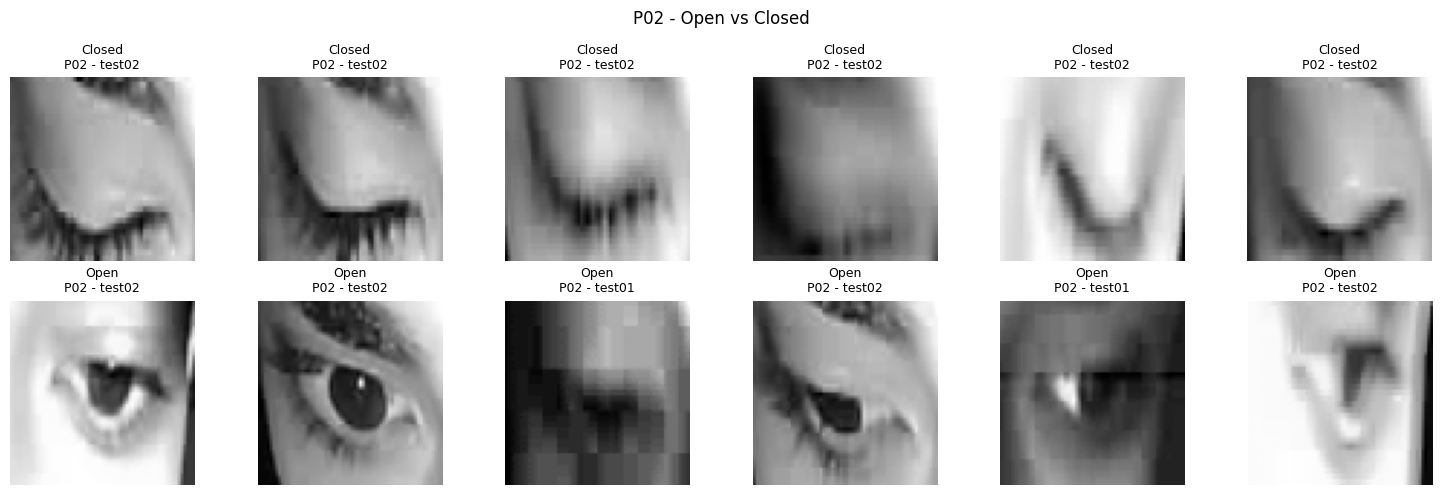

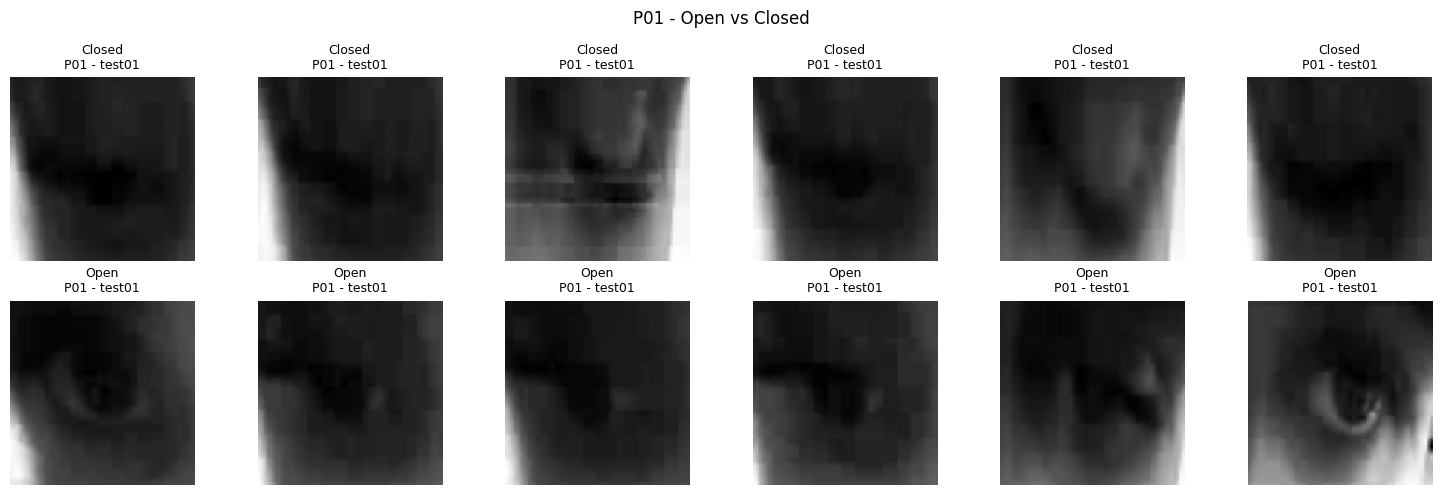

In [53]:

import matplotlib.pyplot as plt
import random
from PIL import Image

def show_samples(data, title, samples_per_class=6):

    fig, axes = plt.subplots(
        2, samples_per_class,
        figsize=(15, 5)
    )

    for row, label in enumerate([0, 1]):

        subset = data[data["label"] == label]

        selected = subset.sample(
            min(samples_per_class, len(subset)),
            random_state=42
        )

        for col, (_, record) in enumerate(selected.iterrows()):

            img = Image.open(
                record["image_path"]
            ).convert("L")

            axes[row, col].imshow(img, cmap="gray")
            axes[row, col].axis("off")

            class_name = "Open" if label == 1 else "Closed"

            axes[row, col].set_title(
                f"{class_name}\n{record['subject_id']} - "
                f"{record['session_id']}",
                fontsize=9
            )

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Compare sessions of the same subject
show_samples(
    df[df["subject_id"] == "P02"],
    "P02 - Open vs Closed"
)

# Compare different subjects
show_samples(
    df[df["subject_id"] == "P01"],
    "P01 - Open vs Closed"
)


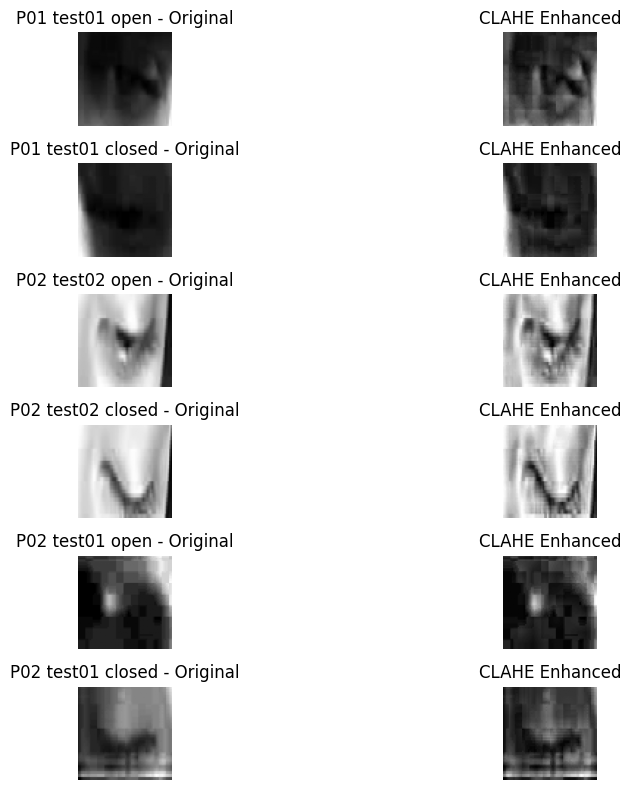

In [54]:
!pip install opencv-python-headless -q

import cv2
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

def apply_clahe(image_path):

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(img)

    return img, enhanced


# Select sample images from different sessions
samples = df.groupby(
    ["subject_id", "session_id", "class_name"],
    group_keys=False
).head(1)

plt.figure(figsize=(12, 8))

for i, (_, row) in enumerate(samples.iterrows()):

    original, enhanced = apply_clahe(row["image_path"])

    plt.subplot(len(samples), 2, 2*i + 1)
    plt.imshow(original, cmap="gray")
    plt.title(
        f'{row["subject_id"]} {row["session_id"]} '
        f'{row["class_name"]} - Original'
    )
    plt.axis("off")

    plt.subplot(len(samples), 2, 2*i + 2)
    plt.imshow(enhanced, cmap="gray")
    plt.title("CLAHE Enhanced")
    plt.axis("off")

plt.tight_layout()
plt.show()

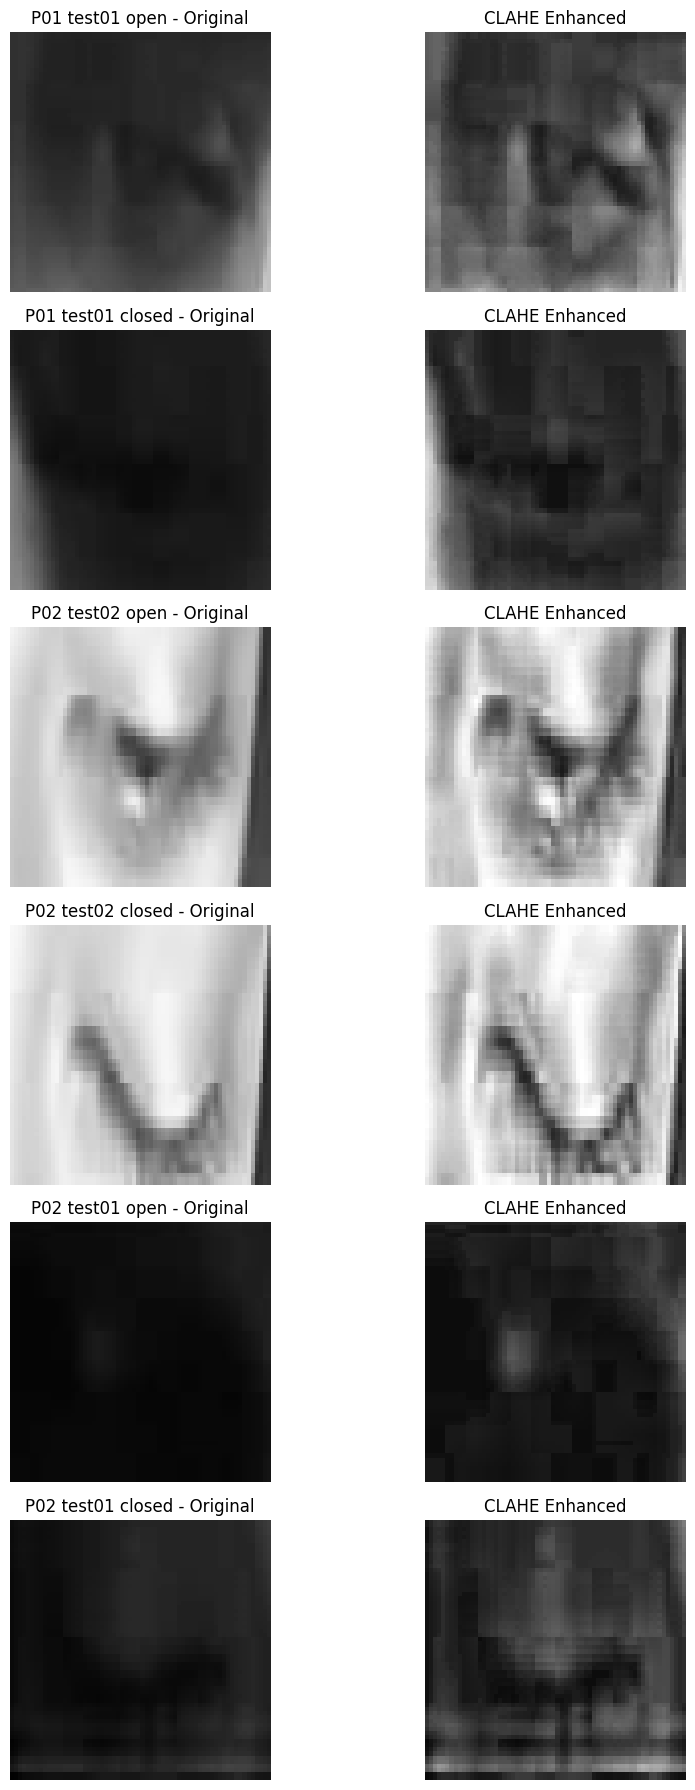

In [55]:

!pip install opencv-python-headless -q

import cv2
import matplotlib.pyplot as plt
import numpy as np

def apply_clahe(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(img)

    return img, enhanced


# Select one image from each subject/session/class
samples = (
    df.groupby(
        ["subject_id", "session_id", "class_name"]
    )
    .head(1)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    len(samples), 2,
    figsize=(10, 3 * len(samples))
)

for i, row in samples.iterrows():

    original, enhanced = apply_clahe(row["image_path"])

    axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(
        f'{row["subject_id"]} {row["session_id"]} '
        f'{row["class_name"]} - Original'
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(enhanced, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("CLAHE Enhanced")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [56]:

def calculate_brightness(image_path):

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    return {
        "mean_brightness": np.mean(img),
        "std_brightness": np.std(img)
    }


brightness_records = []

for _, row in df.iterrows():

    stats = calculate_brightness(row["image_path"])

    brightness_records.append({
        "subject": row["subject_id"],
        "session": row["session_id"],
        "class": row["class_name"],
        **stats
    })

brightness_df = pd.DataFrame(brightness_records)

print("Brightness by subject and session:")

display(
    brightness_df.groupby(
        ["subject", "session"]
    )[["mean_brightness", "std_brightness"]]
    .mean()
    .round(2)
)


Brightness by subject and session:


mean_brightness  std_brightness
subject session                                 
P01     test01             46.34           23.86
P02     test01             31.27           13.01
        test02            154.41           44.84

In [57]:

import cv2
import numpy as np
import pandas as pd

def get_clahe_brightness(path):

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(img)

    return np.mean(enhanced), np.std(enhanced)


records = []

for _, row in df.iterrows():

    mean_value, std_value = get_clahe_brightness(
        row["image_path"]
    )

    records.append({
        "subject": row["subject_id"],
        "session": row["session_id"],
        "mean": mean_value,
        "std": std_value
    })


clahe_df = pd.DataFrame(records)

print("CLAHE brightness by session:")

display(
    clahe_df.groupby(["subject", "session"])[
        ["mean", "std"]
    ].mean().round(2)
)


CLAHE brightness by session:


mean    std
subject session               
P01     test01    69.60  32.97
P02     test01    55.49  22.79
        test02   156.40  49.33

In [58]:

import cv2
import numpy as np
import pandas as pd

def normalize_brightness(image_path):

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    p2, p98 = np.percentile(img, (2, 98))

    if p98 <= p2:
        return img

    normalized = np.clip(
        (img.astype(np.float32) - p2) /
        (p98 - p2),
        0, 1
    )

    normalized = (normalized * 255).astype(np.uint8)

    return normalized


records = []

for _, row in df.iterrows():

    img = normalize_brightness(row["image_path"])

    records.append({
        "subject": row["subject_id"],
        "session": row["session_id"],
        "mean": np.mean(img),
        "std": np.std(img)
    })


normalized_df = pd.DataFrame(records)

print("Normalized brightness by session:")

display(
    normalized_df.groupby(["subject", "session"])[
        ["mean", "std"]
    ].mean().round(2)
)


Normalized brightness by session:


mean    std
subject session               
P01     test01    57.36  54.24
P02     test01   108.56  66.97
        test02   153.08  66.05

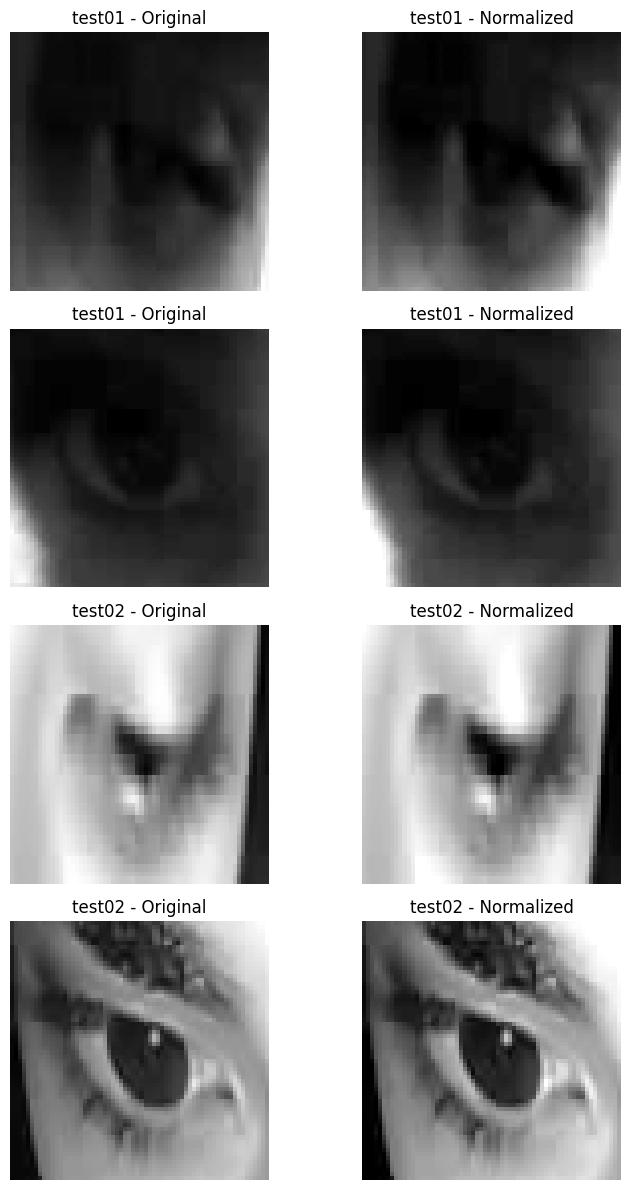

In [59]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

samples = []

for session in ["test01", "test02"]:
    subset = df[df["session_id"] == session].head(2)

    for _, row in subset.iterrows():
        original = cv2.imread(
            row["image_path"],
            cv2.IMREAD_GRAYSCALE
        )

        normalized = normalize_brightness(row["image_path"])

        samples.append((session, original, normalized))

fig, axes = plt.subplots(len(samples), 2, figsize=(8, 12))

for i, (session, original, normalized) in enumerate(samples):
    axes[i, 0].imshow(original, cmap="gray")
    axes[i, 0].set_title(f"{session} - Original")

    axes[i, 1].imshow(normalized, cmap="gray")
    axes[i, 1].set_title(f"{session} - Normalized")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [60]:
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D,
    GlobalAveragePooling2D,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 30

tf.keras.utils.set_random_seed(SEED)

def normalize_brightness(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise ValueError(f"Cannot read image: {image_path}")

    p2, p98 = np.percentile(img, (2, 98))

    if p98 <= p2:
        return img

    normalized = np.clip(
        (img.astype(np.float32) - p2) / (p98 - p2),
        0, 1
    )

    return (normalized * 255).astype(np.uint8)

print("Libraries and normalization function ready.")


Libraries and normalization function ready.


In [61]:
def load_normalized_images(dataframe):

    X = []
    y = []

    for _, row in dataframe.iterrows():

        img = normalize_brightness(row["image_path"])

        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

        img = img.astype(np.float32) / 255.0

        X.append(img)
        y.append(1 if row["label"].lower() == "open" else 0)

    X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    y = np.array(y)

    return X, y

print("Image loading function ready.")

Image loading function ready.


In [62]:
def create_model():

    model = Sequential([
        tf.keras.layers.Input(shape=(64, 64, 1)),

        Conv2D(32, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation="relu", padding="same"),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation="relu", padding="same"),

        GlobalAveragePooling2D(),

        Dense(64, activation="relu"),
        Dropout(0.3),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("CNN model function ready.")


CNN model function ready.


In [63]:
def train_and_evaluate(X_train, y_train, X_val, y_val,
                       X_test, y_test, experiment_name):

    model = create_model()

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    print(f"\n{experiment_name} Results")
    print("=" * 45)

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, zero_division=0))
    print("F1 Score:", f1_score(y_test, predictions, zero_division=0))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["Closed", "Open"],
        zero_division=0
    ))

    return model, history

print("Training and evaluation function ready.")

Training and evaluation function ready.


In [64]:
# Training: P02 / test01
# Testing: P02 / test02

train_A = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test01")
].copy()

test_A = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test02")
].copy()

# Pair-level split
pairs_A = train_A["pair_id"].unique()

train_pairs_A, val_pairs_A = train_test_split(
    pairs_A,
    test_size=0.20,
    random_state=SEED
)

train_A_final = train_A[
    train_A["pair_id"].isin(train_pairs_A)
]

val_A = train_A[
    train_A["pair_id"].isin(val_pairs_A)
]

X_train_A, y_train_A = load_normalized_images(train_A_final)
X_val_A, y_val_A = load_normalized_images(val_A)
X_test_A, y_test_A = load_normalized_images(test_A)

print("Train:", len(X_train_A))
print("Validation:", len(X_val_A))
print("Test:", len(X_test_A))

model_A_norm, history_A_norm = train_and_evaluate(
    X_train_A, y_train_A,
    X_val_A, y_val_A,
    X_test_A, y_test_A,
    "Experiment A - Normalized Session Based"
)

AttributeError: 'int' object has no attribute 'lower'

In [65]:
def load_normalized_images(dataframe):

    X = []
    y = []

    for _, row in dataframe.iterrows():

        img = normalize_brightness(row["image_path"])
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img = img.astype(np.float32) / 255.0

        X.append(img)

        # Labels are already numeric
        y.append(int(row["label"]))

    X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    y = np.array(y)

    return X, y

print("Image loading function updated successfully.")

Image loading function updated successfully.


In [66]:
# Training: P02 / test01
# Testing: P02 / test02

train_A = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test01")
].copy()

test_A = df[
    (df["subject_id"] == "P02") &
    (df["session_id"] == "test02")
].copy()

# Pair-level split
pairs_A = train_A["pair_id"].unique()

train_pairs_A, val_pairs_A = train_test_split(
    pairs_A,
    test_size=0.20,
    random_state=SEED
)

train_A_final = train_A[
    train_A["pair_id"].isin(train_pairs_A)
]

val_A = train_A[
    train_A["pair_id"].isin(val_pairs_A)
]

X_train_A, y_train_A = load_normalized_images(train_A_final)
X_val_A, y_val_A = load_normalized_images(val_A)
X_test_A, y_test_A = load_normalized_images(test_A)

print("Train:", len(X_train_A))
print("Validation:", len(X_val_A))
print("Test:", len(X_test_A))

model_A_norm, history_A_norm = train_and_evaluate(
    X_train_A, y_train_A,
    X_val_A, y_val_A,
    X_test_A, y_test_A,
    "Experiment A - Normalized Session Based"
)

Train: 224
Validation: 56
Test: 386
Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 14s 866ms/step - accuracy: 0.4152 - loss: 0.6942 - val_accuracy: 0.5357 - val_loss: 0.6922
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 816ms/step - accuracy: 0.5134 - loss: 0.6929 - val_accuracy: 0.5357 - val_loss: 0.6911
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 272ms/step - accuracy: 0.5089 - loss: 0.6933 - val_accuracy: 0.5357 - val_loss: 0.6904
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 275ms/step - accuracy: 0.5045 - loss: 0.6930 - val_accuracy: 0.5179 - val_loss: 0.6898
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 486ms/step - accuracy: 0.5491 - loss: 0.6915 - val_accuracy: 0.5179 - val_loss: 0.6886
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 272ms/step - accuracy: 0.5045 - loss: 0.6899 - val_accuracy: 0.5357 - val_loss: 0.6856
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 273ms/step - accuracy: 0.5312 - loss: 0.6882 - val_accuracy: 0.6607 - val_loss: 0.6827
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 418ms/step - accuracy: 0.5536 - loss: 0.68

In [67]:
# Training: All P02 sessions
# Testing: P01

train_B = df[
    df["subject_id"] == "P02"
].copy()

test_B = df[
    df["subject_id"] == "P01"
].copy()

# Pair-level split
pairs_B = train_B["pair_id"].unique()

train_pairs_B, val_pairs_B = train_test_split(
    pairs_B,
    test_size=0.20,
    random_state=SEED
)

train_B_final = train_B[
    train_B["pair_id"].isin(train_pairs_B)
]

val_B = train_B[
    train_B["pair_id"].isin(val_pairs_B)
]

X_train_B, y_train_B = load_normalized_images(train_B_final)
X_val_B, y_val_B = load_normalized_images(val_B)
X_test_B, y_test_B = load_normalized_images(test_B)

print("Train:", len(X_train_B))
print("Validation:", len(X_val_B))
print("Test:", len(X_test_B))

model_B_norm, history_B_norm = train_and_evaluate(
    X_train_B, y_train_B,
    X_val_B, y_val_B,
    X_test_B, y_test_B,
    "Experiment B - Normalized Subject Based"
)


Train: 532
Validation: 134
Test: 46
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 15s 614ms/step - accuracy: 0.4962 - loss: 0.6944 - val_accuracy: 0.4328 - val_loss: 0.6945
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 321ms/step - accuracy: 0.5113 - loss: 0.6913 - val_accuracy: 0.4328 - val_loss: 0.6951
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 313ms/step - accuracy: 0.5075 - loss: 0.6904 - val_accuracy: 0.4328 - val_loss: 0.6910
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 309ms/step - accuracy: 0.5376 - loss: 0.6876 - val_accuracy: 0.4328 - val_loss: 0.6872
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step - accuracy: 0.5470 - loss: 0.6806 - val_accuracy: 0.6791 - val_loss: 0.6699
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 348ms/step - accuracy: 0.6053 - loss: 0.6698 - val_accuracy: 0.6567 - val_loss: 0.6565
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 260ms/step - accuracy: 0.5977 - loss: 0.6595 - val_accuracy: 0.7015 - val_loss: 0.6311
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 376ms/step - accuracy: 0.6

In [68]:
def load_clahe_images(dataframe):

    X = []
    y = []

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    for _, row in dataframe.iterrows():

        img = cv2.imread(
            row["image_path"],
            cv2.IMREAD_GRAYSCALE
        )

        if img is None:
            raise ValueError(f"Cannot read: {row['image_path']}")

        img = clahe.apply(img)

        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img = img.astype(np.float32) / 255.0

        X.append(img)
        y.append(int(row["label"]))

    X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    y = np.array(y)

    return X, y

print("CLAHE loader ready.")

CLAHE loader ready.


In [69]:
# Load CLAHE images using the same previous splits

X_train_A_clahe, y_train_A_clahe = load_clahe_images(train_A_final)

X_val_A_clahe, y_val_A_clahe = load_clahe_images(val_A)

X_test_A_clahe, y_test_A_clahe = load_clahe_images(test_A)

print("Train:", len(X_train_A_clahe))
print("Validation:", len(X_val_A_clahe))
print("Test:", len(X_test_A_clahe))

model_A_clahe, history_A_clahe = train_and_evaluate(
    X_train_A_clahe, y_train_A_clahe,
    X_val_A_clahe, y_val_A_clahe,
    X_test_A_clahe, y_test_A_clahe,
    "Experiment A - CLAHE Session Based"
)

Train: 224
Validation: 56
Test: 386
Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 598ms/step - accuracy: 0.5000 - loss: 0.6943 - val_accuracy: 0.4643 - val_loss: 0.6934
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 458ms/step - accuracy: 0.5134 - loss: 0.6923 - val_accuracy: 0.4643 - val_loss: 0.6933
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 493ms/step - accuracy: 0.5045 - loss: 0.6920 - val_accuracy: 0.4107 - val_loss: 0.6932
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - accuracy: 0.4955 - loss: 0.6933 - val_accuracy: 0.4286 - val_loss: 0.6927
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - accuracy: 0.5134 - loss: 0.6919 - val_accuracy: 0.4464 - val_loss: 0.6924
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - accuracy: 0.5268 - loss: 0.6898 - val_accuracy: 0.4643 - val_loss: 0.6920
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 358ms/step - accuracy: 0.5179 - loss: 0.6917 - val_accuracy: 0.5714 - val_loss: 0.6903
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 347ms/step - accuracy: 0.5580 - loss: 0.692


Experiment A - CLAHE Session Based Results
Accuracy: 0.6735751295336787
Precision: 0.6312056737588653
Recall: 0.89
F1 Score: 0.7385892116182573

Confusion Matrix:
[[ 82 104]
 [ 22 178]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.79      0.44      0.57       186
        Open       0.63      0.89      0.74       200

    accuracy                           0.67       386
   macro avg       0.71      0.67      0.65       386
weighted avg       0.71      0.67      0.66       386



In [70]:
# Load CLAHE images using the same previous splits

X_train_B_clahe, y_train_B_clahe = load_clahe_images(train_B_final)

X_val_B_clahe, y_val_B_clahe = load_clahe_images(val_B)

X_test_B_clahe, y_test_B_clahe = load_clahe_images(test_B)

print("Train:", len(X_train_B_clahe))
print("Validation:", len(X_val_B_clahe))
print("Test:", len(X_test_B_clahe))

model_B_clahe, history_B_clahe = train_and_evaluate(
    X_train_B_clahe, y_train_B_clahe,
    X_val_B_clahe, y_val_B_clahe,
    X_test_B_clahe, y_test_B_clahe,
    "Experiment B - CLAHE Subject Based"
)

Train: 532
Validation: 134
Test: 46
Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 15s 468ms/step - accuracy: 0.5019 - loss: 0.6946 - val_accuracy: 0.4328 - val_loss: 0.6933
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 279ms/step - accuracy: 0.5169 - loss: 0.6916 - val_accuracy: 0.4328 - val_loss: 0.6943
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step - accuracy: 0.5263 - loss: 0.6876 - val_accuracy: 0.4328 - val_loss: 0.6889
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 378ms/step - accuracy: 0.5320 - loss: 0.6838 - val_accuracy: 0.4925 - val_loss: 0.6749
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 259ms/step - accuracy: 0.5752 - loss: 0.6701 - val_accuracy: 0.4328 - val_loss: 0.6927
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 376ms/step - accuracy: 0.6015 - loss: 0.6495 - val_accuracy: 0.5224 - val_loss: 0.6273
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 259ms/step - accuracy: 0.6880 - loss: 0.6164 - val_accuracy: 0.5373 - val_loss: 0.6144
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step - accuracy: 0.6

In [71]:
comparison = pd.DataFrame([
    {
        "Experiment": "A - Session Based",
        "Preprocessing": "Original",
        "Accuracy": 0.5492,
        "Precision": 0.5351,
        "Recall": 0.9900,
        "F1 Score": 0.6947
    },
    {
        "Experiment": "A - Session Based",
        "Preprocessing": "Normalization",
        "Accuracy": 0.6500,
        "Precision": 0.7100,
        "Recall": 0.4000,
        "F1 Score": 0.6200
    },
    {
        "Experiment": "A - Session Based",
        "Preprocessing": "CLAHE",
        "Accuracy": 0.6736,
        "Precision": 0.6312,
        "Recall": 0.8900,
        "F1 Score": 0.7386
    },
    {
        "Experiment": "B - Subject Based",
        "Preprocessing": "Original",
        "Accuracy": 0.5217,
        "Precision": 1.0000,
        "Recall": 0.2143,
        "F1 Score": 0.3529
    },
    {
        "Experiment": "B - Subject Based",
        "Preprocessing": "Normalization",
        "Accuracy": 0.3478,
        "Precision": 0.3750,
        "Recall": 0.1071,
        "F1 Score": 0.1667
    },
    {
        "Experiment": "B - Subject Based",
        "Preprocessing": "CLAHE",
        "Accuracy": 0.5217,
        "Precision": 0.8000,
        "Recall": 0.2857,
        "F1 Score": 0.4211
    }
])

display(comparison.round(4))

,Experiment,Preprocessing,Accuracy,Precision,Recall,F1 Score
0,A - Session Based,Original,0.5492,0.5351,0.9900,0.6947
1,A - Session Based,Normalization,0.6500,0.7100,0.4000,0.6200
2,A - Session Based,CLAHE,0.6736,0.6312,0.8900,0.7386
3,B - Subject Based,Original,0.5217,1.0000,0.2143,0.3529
4,B - Subject Based,Normalization,0.3478,0.3750,0.1071,0.1667
5,B - Subject Based,CLAHE,0.5217,0.8000,0.2857,0.4211


In [72]:
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np

sessions = {
    "P01_test01": test_B,
    "P02_test01": train_A,
    "P02_test02": test_A
}

session_results = []

for session_name, session_df in sessions.items():

    X_session, y_session = load_clahe_images(session_df)

    predictions = model_A_clahe.predict(
        X_session, verbose=0
    ).ravel()

    predictions = (predictions >= 0.5).astype(int)

    accuracy = accuracy_score(y_session, predictions)

    session_results.append({
        "Session": session_name,
        "Images": len(y_session),
        "Accuracy": accuracy
    })

session_results_df = pd.DataFrame(session_results)

display(session_results_df)

,Session,Images,Accuracy
0,P01_test01,46,0.195652
1,P02_test01,280,0.760714
2,P02_test02,386,0.673575


In [73]:
for session_name, session_df in sessions.items():

    X_session, y_session = load_clahe_images(session_df)

    predictions = (
        model_A_clahe.predict(X_session, verbose=0).ravel() >= 0.5
    ).astype(int)

    print("\n", session_name)
    print("=" * 40)

    print(classification_report(
        y_session,
        predictions,
        target_names=["Closed", "Open"],
        zero_division=0
    ))


 P01_test01
              precision    recall  f1-score   support

      Closed       0.21      0.39      0.27        18
        Open       0.15      0.07      0.10        28

    accuracy                           0.20        46
   macro avg       0.18      0.23      0.19        46
weighted avg       0.18      0.20      0.17        46


 P02_test01
              precision    recall  f1-score   support

      Closed       0.74      0.83      0.78       144
        Open       0.79      0.69      0.74       136

    accuracy                           0.76       280
   macro avg       0.76      0.76      0.76       280
weighted avg       0.76      0.76      0.76       280


 P02_test02
              precision    recall  f1-score   support

      Closed       0.79      0.44      0.57       186
        Open       0.63      0.89      0.74       200

    accuracy                           0.67       386
   macro avg       0.71      0.67      0.65       386
weighted avg       0.71      0.67  

In [74]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

# Augmentation applied to training images only
datagen = ImageDataGenerator(
    brightness_range=(0.7, 1.3)
)

model_B_aug = create_model()

early_stop_aug = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_B_aug = model_B_aug.fit(
    datagen.flow(
        X_train_B_clahe,
        y_train_B_clahe,
        batch_size=32,
        shuffle=True,
        seed=42
    ),
    validation_data=(
        X_val_B_clahe,
        y_val_B_clahe
    ),
    epochs=30,
    callbacks=[early_stop_aug],
    verbose=1
)

# Evaluate on the original, unaugmented test images
probabilities_B_aug = model_B_aug.predict(
    X_test_B_clahe,
    verbose=0
).ravel()

predictions_B_aug = (
    probabilities_B_aug >= 0.5
).astype(int)

print("\nExperiment B - CLAHE + Brightness Augmentation")
print("=" * 55)

print("Accuracy:",
      accuracy_score(y_test_B_clahe, predictions_B_aug))

print("Precision:",
      precision_score(y_test_B_clahe, predictions_B_aug, zero_division=0))

print("Recall:",
      recall_score(y_test_B_clahe, predictions_B_aug, zero_division=0))

print("F1 Score:",
      f1_score(y_test_B_clahe, predictions_B_aug, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_B_clahe, predictions_B_aug))

print("\nClassification Report:")
print(classification_report(
    y_test_B_clahe,
    predictions_B_aug,
    target_names=["Closed", "Open"],
    zero_division=0
))

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 473ms/step - accuracy: 0.5113 - loss: 0.6932 - val_accuracy: 0.4328 - val_loss: 0.6945
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 321ms/step - accuracy: 0.5244 - loss: 0.6930 - val_accuracy: 0.4328 - val_loss: 0.6964
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 281ms/step - accuracy: 0.5226 - loss: 0.6921 - val_accuracy: 0.4328 - val_loss: 0.6974
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 374ms/step - accuracy: 0.5226 - loss: 0.6922 - val_accuracy: 0.4328 - val_loss: 0.7424
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 262ms/step - accuracy: 0.5226 - loss: 0.6916 - val_accuracy: 0.4328 - val_loss: 0.7166
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 435ms/step - accuracy: 0.5169 - loss: 0.6932 - val_accuracy: 0.4328 - val_loss: 0.7023

Experiment B - CLAHE + Brightness Augmentation
Accuracy: 0.6086956521739131
Precision: 0.6086956521739131
Recall: 1.0
F1 Score: 0.7567567567567568

Confusion Matrix:
[[ 0 18]
 [ 0 28]]

Classification Report:
              precisi

In [75]:
from sklearn.metrics import f1_score
import numpy as np

# Predictions on validation data only
val_probs = model_B_aug.predict(
    X_val_B_clahe,
    verbose=0
).ravel()

threshold_results = []

for threshold in np.arange(0.1, 0.91, 0.05):

    val_preds = (val_probs >= threshold).astype(int)

    f1_macro = f1_score(
        y_val_B_clahe,
        val_preds,
        average="macro",
        zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Macro_F1": f1_macro
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        "Macro_F1",
        ascending=False
    )
)

,Threshold,Macro_F1
16,0.90,0.361905
12,0.70,0.361905
15,0.85,0.361905
14,0.80,0.361905
13,0.75,0.361905
10,0.60,0.361905
11,0.65,0.361905
9,0.55,0.361905
0,0.10,0.302083
8,0.50,0.302083


In [76]:
best_threshold = threshold_df.loc[
    threshold_df["Macro_F1"].idxmax(),
    "Threshold"
]

print("Best Validation Threshold:", best_threshold)

Best Validation Threshold: 0.55


In [77]:
test_probs = model_B_aug.predict(
    X_test_B_clahe,
    verbose=0
).ravel()

test_preds = (
    test_probs >= best_threshold
).astype(int)

print("Test Accuracy:",
      accuracy_score(y_test_B_clahe, test_preds))

print("Test Macro F1:",
      f1_score(
          y_test_B_clahe,
          test_preds,
          average="macro",
          zero_division=0
      ))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_B_clahe, test_preds))

print("\nClassification Report:")
print(classification_report(
    y_test_B_clahe,
    test_preds,
    target_names=["Closed", "Open"],
    zero_division=0
))

Test Accuracy: 0.391304347826087
Test Macro F1: 0.28125

Confusion Matrix:
[[18  0]
 [28  0]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.39      1.00      0.56        18
        Open       0.00      0.00      0.00        28

    accuracy                           0.39        46
   macro avg       0.20      0.50      0.28        46
weighted avg       0.15      0.39      0.22        46



In [78]:
import pandas as pd
import numpy as np

val_probs = model_B_aug.predict(
    X_val_B_clahe,
    verbose=0
).ravel()

val_analysis = pd.DataFrame({
    "Actual_Label": y_val_B_clahe,
    "Predicted_Probability": val_probs
})

val_analysis["Class"] = val_analysis["Actual_Label"].map({
    0: "Closed",
    1: "Open"
})

print("Probability Statistics by Class:")

display(
    val_analysis.groupby("Class")[
        "Predicted_Probability"
    ].agg([
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ]).round(4)
)

Probability Statistics by Class:


,count,mean,std,min,median,max
Class,,,,,,
Closed,76,0.5086,0.0026,0.5045,0.5087,0.5125
Open,58,0.5100,0.0024,0.5046,0.5108,0.5127


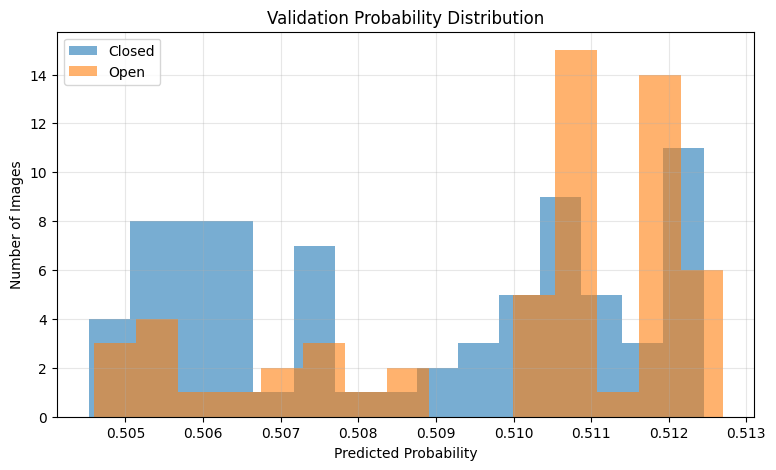

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    val_analysis[
        val_analysis["Class"] == "Closed"
    ]["Predicted_Probability"],
    bins=15,
    alpha=0.6,
    label="Closed"
)

plt.hist(
    val_analysis[
        val_analysis["Class"] == "Open"
    ]["Predicted_Probability"],
    bins=15,
    alpha=0.6,
    label="Open"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Number of Images")
plt.title("Validation Probability Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [80]:
import pandas as pd
import numpy as np

val_probs = model_B_aug.predict(
    X_val_B_clahe,
    verbose=0
).ravel()

val_analysis = pd.DataFrame({
    "Actual_Label": y_val_B_clahe,
    "Probability": val_probs
})

for label, name in [(0, "Closed"), (1, "Open")]:

    values = val_analysis[
        val_analysis["Actual_Label"] == label
    ]["Probability"]

    print("\n", name)
    print("=" * 35)
    print("Count:", len(values))
    print("Mean:", round(values.mean(), 4))
    print("Std:", round(values.std(), 4))
    print("Minimum:", round(values.min(), 4))
    print("25%:", round(values.quantile(0.25), 4))
    print("Median:", round(values.median(), 4))
    print("75%:", round(values.quantile(0.75), 4))
    print("Maximum:", round(values.max(), 4))

print("\nValidation Labels:")
print("Closed:", np.sum(y_val_B_clahe == 0))
print("Open:", np.sum(y_val_B_clahe == 1))


 Closed
Count: 76
Mean: 0.5086
Std: 0.0026
Minimum: 0.5045
25%: 0.5061
Median: 0.5087
75%: 0.5108
Maximum: 0.5125

 Open
Count: 58
Mean: 0.51
Std: 0.0024
Minimum: 0.5046
25%: 0.5081
Median: 0.5108
75%: 0.5119
Maximum: 0.5127

Validation Labels:
Closed: 76
Open: 58


In [81]:
print("========== LABEL CHECK ==========")

print(df["label"].value_counts())

print("\n========== SUBJECT CHECK ==========")

print(df.groupby("subject_id")["label"].value_counts())

print("\n========== SESSION CHECK ==========")

print(
    df.groupby(["subject_id", "session_id"])["label"]
    .value_counts()
)

print("\n========== PAIR CHECK ==========")

pair_check = df.groupby("pair_id").agg(
    image_count=("image_path", "count"),
    label_count=("label", "nunique"),
    subject_count=("subject_id", "nunique"),
    session_count=("session_id", "nunique")
)

print("Total pairs:", len(pair_check))
print("Pairs with 2 images:", (pair_check["image_count"] == 2).sum())
print("Pairs with inconsistent labels:", (pair_check["label_count"] != 1).sum())
print("Pairs with mixed subjects:", (pair_check["subject_count"] != 1).sum())
print("Pairs with mixed sessions:", (pair_check["session_count"] != 1).sum())

========== LABEL CHECK ==========
label
1    364
0    348
Name: count, dtype: int64

========== SUBJECT CHECK ==========
subject_id  label
P01         1         28
            0         18
P02         1        336
            0        330
Name: count, dtype: int64

========== SESSION CHECK ==========
subject_id  session_id  label
P01         test01      1         28
                        0         18
P02         test01      0        144
                        1        136
            test02      1        200
                        0        186
Name: count, dtype: int64

========== PAIR CHECK ==========
Total pairs: 356
Pairs with 2 images: 356
Pairs with inconsistent labels: 0
Pairs with mixed subjects: 0
Pairs with mixed sessions: 0


In [82]:
def probability_summary(model, X, y, name):

    probs = model.predict(X, verbose=0).ravel()

    print("\n", name)
    print("=" * 45)

    for label, class_name in [(0, "Closed"), (1, "Open")]:

        values = probs[y == label]

        print(
            class_name,
            "| Count:", len(values),
            "| Mean:", round(values.mean(), 4),
            "| Std:", round(values.std(), 4),
            "| Min:", round(values.min(), 4),
            "| Max:", round(values.max(), 4)
        )


probability_summary(
    model_B_clahe,
    X_val_B_clahe,
    y_val_B_clahe,
    "CLAHE Model"
)

probability_summary(
    model_B_aug,
    X_val_B_clahe,
    y_val_B_clahe,
    "CLAHE + Augmentation Model"
)


 CLAHE Model
Closed | Count: 76 | Mean: 0.2689 | Std: 0.2194 | Min: 0.0056 | Max: 0.9205
Open | Count: 58 | Mean: 0.8619 | Std: 0.2012 | Min: 0.1631 | Max: 0.9981

 CLAHE + Augmentation Model
Closed | Count: 76 | Mean: 0.5086 | Std: 0.0026 | Min: 0.5045 | Max: 0.5125
Open | Count: 58 | Mean: 0.51 | Std: 0.0024 | Min: 0.5046 | Max: 0.5127


In [83]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

def evaluate_model(model, X, y, name):

    probs = model.predict(X, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy:", accuracy_score(y, preds))
    print("Balanced Accuracy:", balanced_accuracy_score(y, preds))
    print("Macro F1:", f1_score(y, preds, average="macro"))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y, preds))

    print("\nClassification Report:")
    print(classification_report(
        y,
        preds,
        target_names=["Closed", "Open"],
        zero_division=0
    ))

evaluate_model(
    model_B_clahe,
    X_val_B_clahe,
    y_val_B_clahe,
    "CLAHE - Validation"
)

evaluate_model(
    model_B_clahe,
    X_test_B_clahe,
    y_test_B_clahe,
    "CLAHE - Test"
)


CLAHE - Validation
Accuracy: 0.8880597014925373
Balanced Accuracy: 0.8911070780399275
Macro F1: 0.8869961207623545

Confusion Matrix:
[[66 10]
 [ 5 53]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.93      0.87      0.90        76
        Open       0.84      0.91      0.88        58

    accuracy                           0.89       134
   macro avg       0.89      0.89      0.89       134
weighted avg       0.89      0.89      0.89       134


CLAHE - Test
Accuracy: 0.5217391304347826
Balanced Accuracy: 0.5873015873015872
Macro F1: 0.50682261208577

Confusion Matrix:
[[16  2]
 [20  8]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.44      0.89      0.59        18
        Open       0.80      0.29      0.42        28

    accuracy                           0.52        46
   macro avg       0.62      0.59      0.51        46
weighted avg       0.66      0.52      0.49        46

In [84]:
import cv2
import numpy as np
import pandas as pd

def extract_image_features(dataframe):

    records = []

    for _, row in dataframe.iterrows():

        img = cv2.imread(row["image_path"], cv2.IMREAD_GRAYSCALE)

        if img is None:
            continue

        records.append({
            "subject": row["subject_id"],
            "session": row["session_id"],
            "label": row["class_name"],
            "brightness": np.mean(img),
            "contrast": np.std(img),
            "min_pixel": np.min(img),
            "max_pixel": np.max(img),
            "median": np.median(img)
        })

    return pd.DataFrame(records)


image_features = extract_image_features(df)

summary = image_features.groupby(
    ["subject", "session"]
).agg({
    "brightness": ["mean", "std"],
    "contrast": ["mean", "std"],
    "median": "mean",
    "min_pixel": "mean",
    "max_pixel": "mean"
}).round(2)

print(summary)

                brightness        contrast        median min_pixel max_pixel
                      mean    std     mean   std    mean      mean      mean
subject session                                                             
P01     test01       46.34  19.49    23.86  8.24   39.85     18.70    156.54
P02     test01       31.27  14.00    13.01  5.81   30.45      7.11     80.62
        test02      154.41  35.17    44.84  9.56  163.16     26.97    235.96


In [85]:

import cv2
import numpy as np
import pandas as pd

records = []

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

for _, row in df.iterrows():

    img = cv2.imread(
        row["image_path"],
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        continue

    enhanced = clahe.apply(img)

    records.append({
        "subject": row["subject_id"],
        "session": row["session_id"],
        "label": row["class_name"],

        "original_brightness": np.mean(img),
        "original_contrast": np.std(img),

        "clahe_brightness": np.mean(enhanced),
        "clahe_contrast": np.std(enhanced)
    })

features_df = pd.DataFrame(records)

summary = features_df.groupby(
    ["subject", "session", "label"]
).agg({
    "original_brightness": "mean",
    "original_contrast": "mean",
    "clahe_brightness": "mean",
    "clahe_contrast": "mean",
    "label": "count"
}).rename(columns={"label": "image_count"})

print(summary.round(2).to_string())


                        original_brightness  original_contrast  clahe_brightness  clahe_contrast  image_count
subject session label                                                                                        
P01     test01  closed                51.68              28.49             74.69           36.96           18
                open                  42.90              20.89             66.33           30.40           28
P02     test01  closed                30.55              12.46             53.66           21.40          144
                open                  32.03              13.59             57.43           24.26          136
        test02  closed               156.53              40.45            159.11           45.94          186
                open                 152.44              48.92            153.88           52.49          200


In [86]:

import numpy as np

def standardize_images(X, eps=1e-6):

    X = X.astype("float32")

    means = np.mean(X, axis=(1, 2, 3), keepdims=True)
    stds = np.std(X, axis=(1, 2, 3), keepdims=True)

    X_standardized = (X - means) / (stds + eps)

    return X_standardized


X_train_B_std = standardize_images(X_train_B_clahe)
X_val_B_std = standardize_images(X_val_B_clahe)
X_test_B_std = standardize_images(X_test_B_clahe)

print("Train:", X_train_B_std.shape)
print("Validation:", X_val_B_std.shape)
print("Test:", X_test_B_std.shape)

print("\nTrain mean:", round(float(X_train_B_std.mean()), 4))
print("Train std:", round(float(X_train_B_std.std()), 4))

print("\nValidation mean:", round(float(X_val_B_std.mean()), 4))
print("Validation std:", round(float(X_val_B_std.std()), 4))

print("\nTest mean:", round(float(X_test_B_std.mean()), 4))
print("Test std:", round(float(X_test_B_std.std()), 4))


Train: (532, 64, 64, 1)
Validation: (134, 64, 64, 1)
Test: (46, 64, 64, 1)

Train mean: -0.0
Train std: 1.0

Validation mean: -0.0
Validation std: 1.0

Test mean: -0.0
Test std: 1.0


In [87]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Use the cleaned SmartCap metadata
df = smartcap_clean.copy()

# Create a unique key for each eye pair
# This prevents images from the same pair
# from being split between training and validation.

df["_pair_key"] = list(zip(
    df["subject_id"],
    df["session_id"],
    df["pair_id"]
))

# Check pair integrity
pair_table = df.groupby("_pair_key").agg(
    image_count=("image_path", "count"),
    label_count=("label", "nunique"),
    label=("label", "first")
).reset_index()

# Stop if there are incomplete or inconsistent pairs
assert (pair_table["image_count"] == 2).all(), \
    "Error: Some pairs do not contain exactly 2 images."

assert (pair_table["label_count"] == 1).all(), \
    "Error: Some pairs have inconsistent labels."

# Split pairs: 80% Training, 20% Validation
train_pairs, val_pairs = train_test_split(
    pair_table,
    test_size=0.20,
    random_state=42,
    stratify=pair_table["label"]
)

# Assign all images belonging to each pair
train_df = df[
    df["_pair_key"].isin(train_pairs["_pair_key"])
].copy()

val_df = df[
    df["_pair_key"].isin(val_pairs["_pair_key"])
].copy()

# Verify no pair leakage
train_keys = set(train_df["_pair_key"])
val_keys = set(val_df["_pair_key"])

assert len(train_keys.intersection(val_keys)) == 0

# Display results
print("=" * 50)
print("SMARTCAP DATA SPLIT")
print("=" * 50)

print("Total images:", len(df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining percentage:",
      round(len(train_df) / len(df) * 100, 2), "%")

print("Validation percentage:",
      round(len(val_df) / len(df) * 100, 2), "%")

print("\nTraining pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

print("\nTraining class distribution:")
print(train_df["class_name"].value_counts())

print("\nValidation class distribution:")
print(val_df["class_name"].value_counts())

print("\nTraining subject distribution:")
print(train_df["subject_id"].value_counts())

print("\nValidation subject distribution:")
print(val_df["subject_id"].value_counts())

print("\nPair leakage:", len(train_keys.intersection(val_keys)))
print("\nSplit completed successfully.")


SMARTCAP DATA SPLIT
Total images: 712
Training images: 568
Validation images: 144

Training percentage: 79.78 %
Validation percentage: 20.22 %

Training pairs: 284
Validation pairs: 72

Training class distribution:
class_name
open      290
closed    278
Name: count, dtype: int64

Validation class distribution:
class_name
open      74
closed    70
Name: count, dtype: int64

Training subject distribution:
subject_id
P02    530
P01     38
Name: count, dtype: int64

Validation subject distribution:
subject_id
P02    136
P01      8
Name: count, dtype: int64

Pair leakage: 0

Split completed successfully.


In [88]:

import cv2
import numpy as np

IMG_SIZE = 64

# Labels: Closed = 0, Open = 1
label_map = {
    "closed": 0,
    "open": 1
}

def load_images(dataframe, use_clahe=False):

    images = []
    labels = []

    for _, row in dataframe.iterrows():

        img = cv2.imread(
            row["image_path"],
            cv2.IMREAD_GRAYSCALE
        )

        if img is None:
            raise ValueError(
                f"Could not read image: {row['image_path']}"
            )

        img = cv2.resize(
            img,
            (IMG_SIZE, IMG_SIZE)
        )

        if use_clahe:
            clahe = cv2.createCLAHE(
                clipLimit=2.0,
                tileGridSize=(8, 8)
            )
            img = clahe.apply(img)

        img = img.astype("float32") / 255.0

        images.append(img)
        labels.append(label_map[row["class_name"].lower()])

    X = np.array(images, dtype="float32")
    X = X[..., np.newaxis]

    y = np.array(labels, dtype="int32")

    return X, y


# Original images
X_train_original, y_train = load_images(
    train_df,
    use_clahe=False
)

X_val_original, y_val = load_images(
    val_df,
    use_clahe=False
)

# CLAHE images
X_train_clahe, y_train_clahe = load_images(
    train_df,
    use_clahe=True
)

X_val_clahe, y_val_clahe = load_images(
    val_df,
    use_clahe=True
)


# Verify labels are identical
assert np.array_equal(y_train, y_train_clahe)
assert np.array_equal(y_val, y_val_clahe)

print("========== DATASET SHAPES ==========")

print("Original Training:", X_train_original.shape)
print("Original Validation:", X_val_original.shape)

print("CLAHE Training:", X_train_clahe.shape)
print("CLAHE Validation:", X_val_clahe.shape)

print("\n========== LABEL DISTRIBUTION ==========")

print("Training Closed:", np.sum(y_train == 0))
print("Training Open:", np.sum(y_train == 1))

print("Validation Closed:", np.sum(y_val == 0))
print("Validation Open:", np.sum(y_val == 1))

print("\n========== PIXEL RANGE ==========")

print("Original min:", X_train_original.min())
print("Original max:", X_train_original.max())

print("CLAHE min:", X_train_clahe.min())
print("CLAHE max:", X_train_clahe.max())

print("\nData loading completed successfully.")


========== DATASET SHAPES ==========
Original Training: (568, 64, 64, 1)
Original Validation: (144, 64, 64, 1)
CLAHE Training: (568, 64, 64, 1)
CLAHE Validation: (144, 64, 64, 1)

========== LABEL DISTRIBUTION ==========
Training Closed: 278
Training Open: 290
Validation Closed: 70
Validation Open: 74

========== PIXEL RANGE ==========
Original min: 0.0
Original max: 0.99607843
CLAHE min: 0.019607844
CLAHE max: 1.0

Data loading completed successfully.


In [89]:

import tensorflow as tf
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
tf.keras.utils.set_random_seed(42)

# CNN Architecture
model_smartcap_original = Sequential([
    Input(shape=(64, 64, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),

    GlobalAveragePooling2D(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

# Compile
model_smartcap_original.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("========== MODEL SUMMARY ==========")
model_smartcap_original.summary()

print(
    "\nTotal Parameters:",
    model_smartcap_original.count_params()
)

# Early Stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Training
history_smartcap_original = model_smartcap_original.fit(
    X_train_original,
    y_train,
    validation_data=(X_val_original, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Validation Prediction
val_probs_original = model_smartcap_original.predict(
    X_val_original,
    verbose=0
).ravel()

val_preds_original = (
    val_probs_original >= 0.5
).astype(int)

# Evaluation
print("\n========== SMARTCAP ORIGINAL - VALIDATION ==========")

print(
    "Accuracy:",
    accuracy_score(y_val, val_preds_original)
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_val, val_preds_original)
)

print(
    "Precision:",
    precision_score(y_val, val_preds_original, zero_division=0)
)

print(
    "Recall:",
    recall_score(y_val, val_preds_original, zero_division=0)
)

print(
    "Macro F1:",
    f1_score(y_val, val_preds_original, average="macro")
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_preds_original))

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_preds_original,
    target_names=["Closed", "Open"],
    zero_division=0
))

# Save model
model_smartcap_original.save(
    "/content/smartcap_original_80_20.keras"
)

print("\nModel saved successfully.")


========== MODEL SUMMARY ==========


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_8      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)


Total Parameters: 100993
Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 13s 551ms/step - accuracy: 0.5141 - loss: 0.6945 - val_accuracy: 0.5139 - val_loss: 0.6904
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 333ms/step - accuracy: 0.5141 - loss: 0.6933 - val_accuracy: 0.5139 - val_loss: 0.6909
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 265ms/step - accuracy: 0.5106 - loss: 0.6926 - val_accuracy: 0.5139 - val_loss: 0.6901
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 288ms/step - accuracy: 0.5106 - loss: 0.6911 - val_accuracy: 0.5139 - val_loss: 0.6864
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 362ms/step - accuracy: 0.5158 - loss: 0.6899 - val_accuracy: 0.5139 - val_loss: 0.6820
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 334ms/step - accuracy: 0.5405 - loss: 0.6878 - val_accuracy: 0.5139 - val_loss: 0.6795
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 298ms/step - accuracy: 0.5546 - loss: 0.6833 - val_accuracy: 0.5972 - val_loss: 0.6706
Epoch 8/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 264ms/step - accuracy: 0.6056 - los

In [90]:

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

tf.keras.utils.set_random_seed(42)

# New CNN model for CLAHE
model_smartcap_clahe = Sequential([
    Input(shape=(64, 64, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),

    GlobalAveragePooling2D(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model_smartcap_clahe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop_clahe = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train using CLAHE images
history_smartcap_clahe = model_smartcap_clahe.fit(
    X_train_clahe,
    y_train_clahe,
    validation_data=(X_val_clahe, y_val_clahe),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop_clahe],
    verbose=1
)

# Validation prediction
val_probs_clahe = model_smartcap_clahe.predict(
    X_val_clahe,
    verbose=0
).ravel()

val_preds_clahe = (val_probs_clahe >= 0.5).astype(int)

# Evaluation
print("\n========== SMARTCAP CLAHE - VALIDATION ==========")

print("Accuracy:", accuracy_score(y_val_clahe, val_preds_clahe))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_val_clahe, val_preds_clahe))

print("Precision:",
      precision_score(y_val_clahe, val_preds_clahe, zero_division=0))

print("Recall:",
      recall_score(y_val_clahe, val_preds_clahe, zero_division=0))

print("Macro F1:",
      f1_score(y_val_clahe, val_preds_clahe, average="macro"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_clahe, val_preds_clahe))

print("\nClassification Report:")
print(classification_report(
    y_val_clahe,
    val_preds_clahe,
    target_names=["Closed", "Open"],
    zero_division=0
))

model_smartcap_clahe.save(
    "/content/smartcap_clahe_80_20.keras"
)

print("\nCLAHE model saved successfully.")


Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 14s 560ms/step - accuracy: 0.5106 - loss: 0.6940 - val_accuracy: 0.5139 - val_loss: 0.6884
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 393ms/step - accuracy: 0.5123 - loss: 0.6913 - val_accuracy: 0.5139 - val_loss: 0.6855
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 290ms/step - accuracy: 0.5370 - loss: 0.6887 - val_accuracy: 0.5139 - val_loss: 0.6788
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 380ms/step - accuracy: 0.5616 - loss: 0.6818 - val_accuracy: 0.5625 - val_loss: 0.6676
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 268ms/step - accuracy: 0.6021 - loss: 0.6668 - val_accuracy: 0.6597 - val_loss: 0.6359
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 379ms/step - accuracy: 0.6162 - loss: 0.6391 - val_accuracy: 0.7361 - val_loss: 0.5841
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 265ms/step - accuracy: 0.6673 - loss: 0.6094 - val_accuracy: 0.5208 - val_loss: 0.8061
Epoch 8/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 315ms/step - accuracy: 0.5739 - loss: 0.6822 - val_accuracy: 


========== SMARTCAP CLAHE - VALIDATION ==========
Accuracy: 0.9305555555555556
Balanced Accuracy: 0.9312741312741313
Precision: 0.9571428571428572
Recall: 0.9054054054054054
Macro F1: 0.9305555555555556

Confusion Matrix:
[[67  3]
 [ 7 67]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.91      0.96      0.93        70
        Open       0.96      0.91      0.93        74

    accuracy                           0.93       144
   macro avg       0.93      0.93      0.93       144
weighted avg       0.93      0.93      0.93       144


CLAHE model saved successfully.


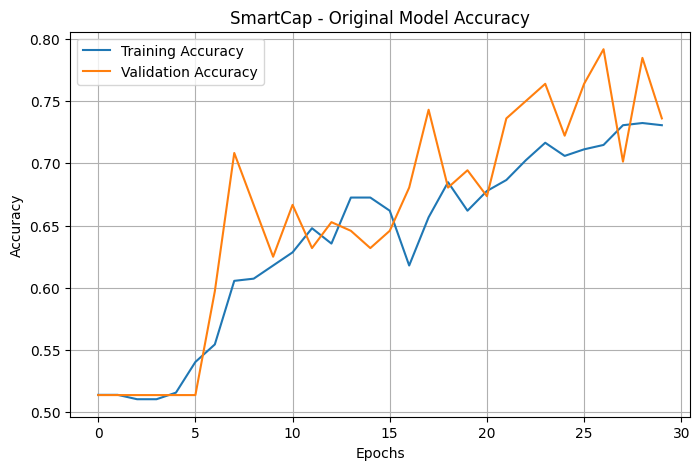

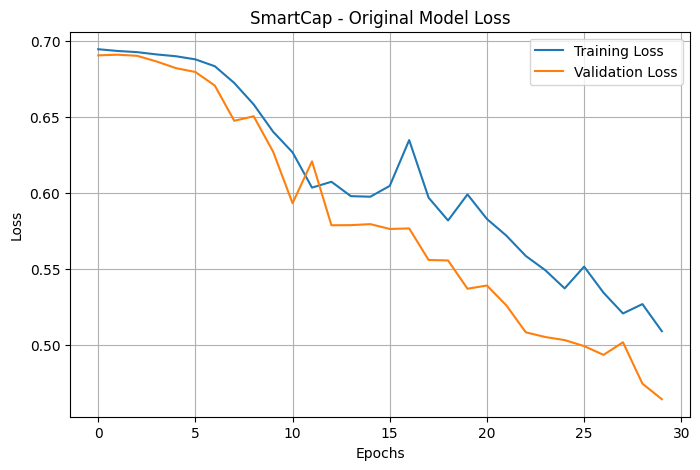

In [91]:

import matplotlib.pyplot as plt

# Original Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history_smartcap_original.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_smartcap_original.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("SmartCap - Original Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Original Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_smartcap_original.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_smartcap_original.history["val_loss"],
    label="Validation Loss"
)

plt.title("SmartCap - Original Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


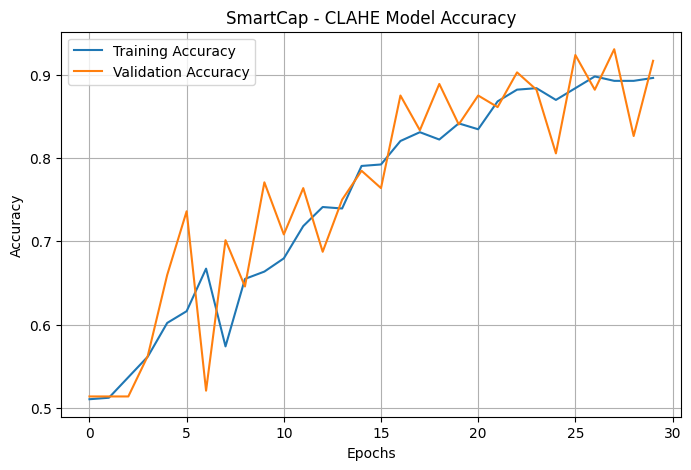

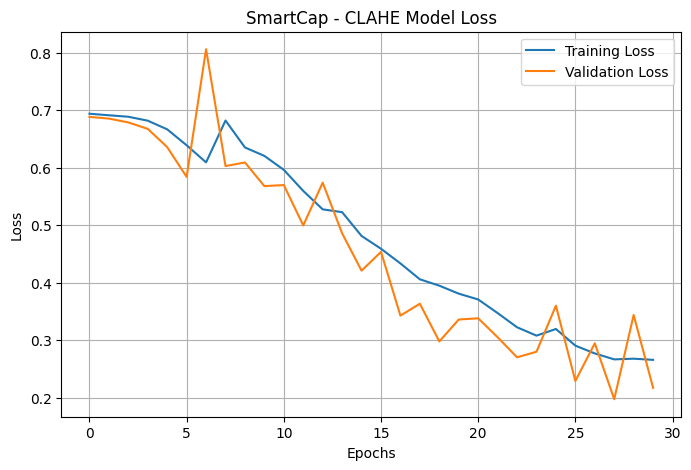

In [92]:

# CLAHE Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history_smartcap_clahe.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_smartcap_clahe.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("SmartCap - CLAHE Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# CLAHE Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_smartcap_clahe.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_smartcap_clahe.history["val_loss"],
    label="Validation Loss"
)

plt.title("SmartCap - CLAHE Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


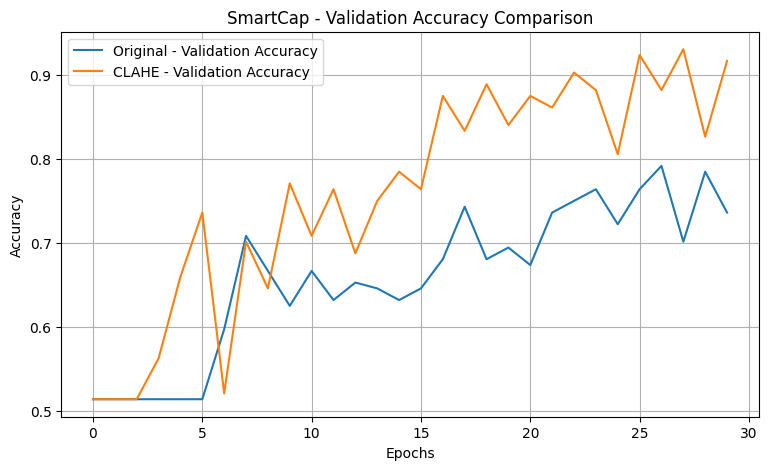

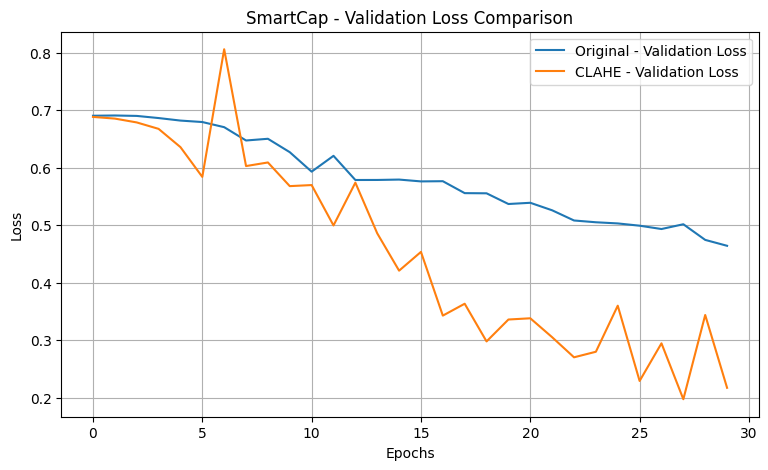

In [93]:

# Compare Validation Accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    history_smartcap_original.history["val_accuracy"],
    label="Original - Validation Accuracy"
)

plt.plot(
    history_smartcap_clahe.history["val_accuracy"],
    label="CLAHE - Validation Accuracy"
)

plt.title("SmartCap - Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Compare Validation Loss
plt.figure(figsize=(9, 5))

plt.plot(
    history_smartcap_original.history["val_loss"],
    label="Original - Validation Loss"
)

plt.plot(
    history_smartcap_clahe.history["val_loss"],
    label="CLAHE - Validation Loss"
)

plt.title("SmartCap - Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


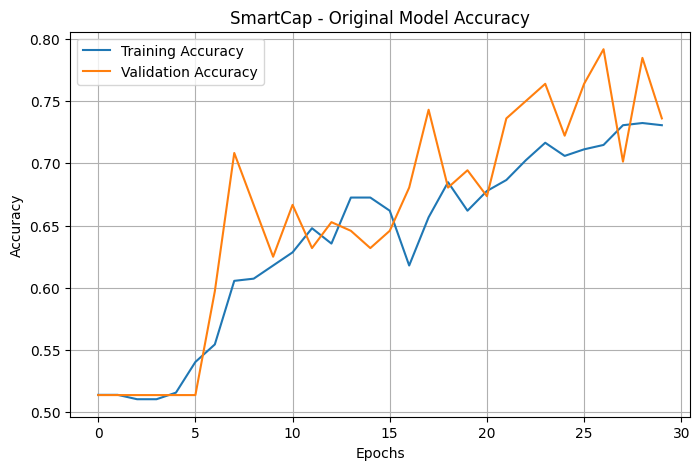

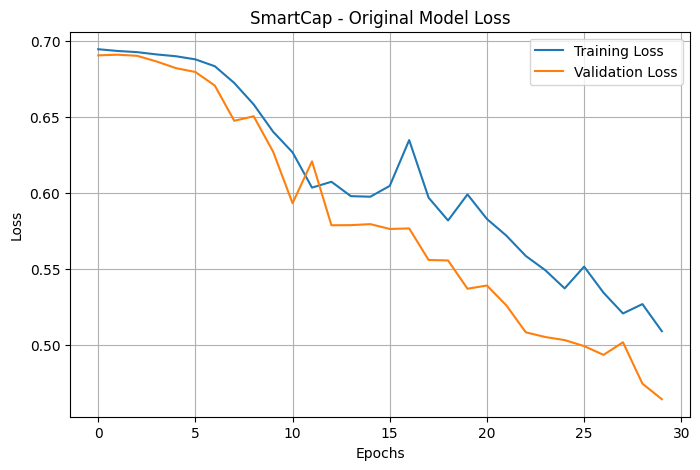

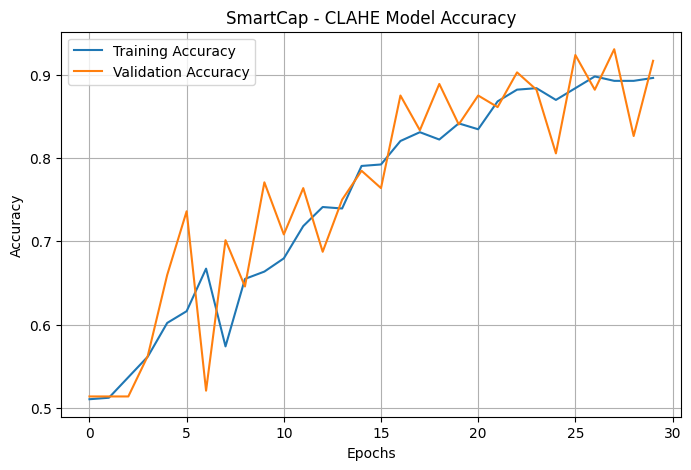

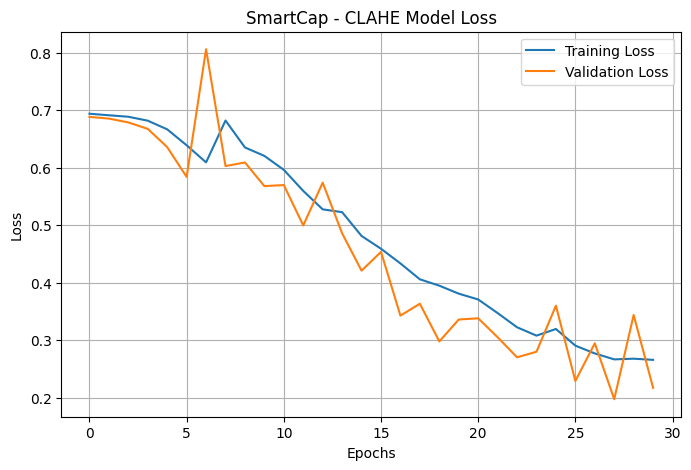

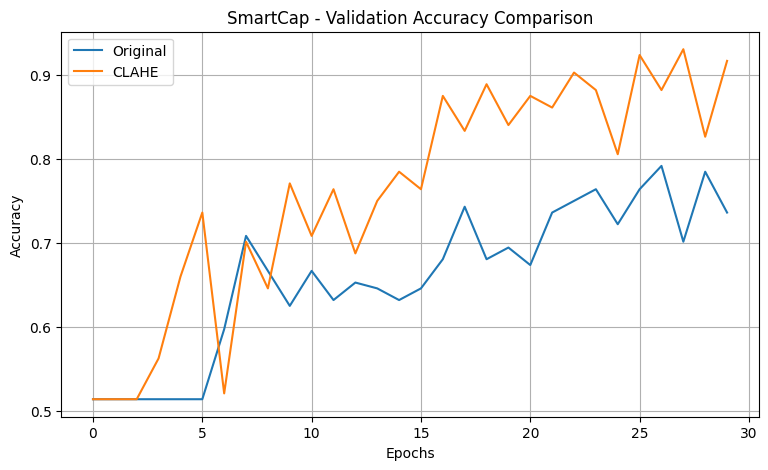

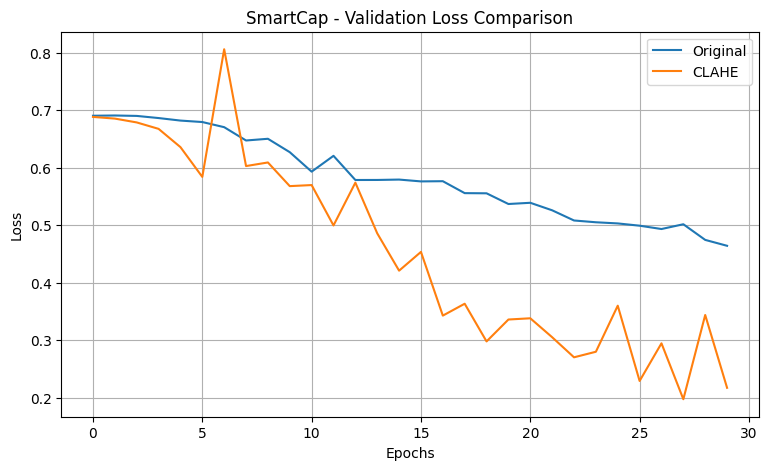

All 6 graphs saved successfully in: /content/SmartCap_CNN/results/graphs


In [94]:
import matplotlib.pyplot as plt
import os

save_dir = "/content/SmartCap_CNN/results/graphs"
os.makedirs(save_dir, exist_ok=True)

histories = {
    "Original": history_smartcap_original,
    "CLAHE": history_smartcap_clahe
}

# Accuracy and Loss for each model
for name, history in histories.items():

    # Accuracy
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"SmartCap - {name} Model Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.savefig(f"{save_dir}/{name}_Accuracy.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Loss
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(f"SmartCap - {name} Model Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.savefig(f"{save_dir}/{name}_Loss.png", dpi=300, bbox_inches="tight")
    plt.show()


# Validation Accuracy Comparison
plt.figure(figsize=(9, 5))
plt.plot(history_smartcap_original.history["val_accuracy"], label="Original")
plt.plot(history_smartcap_clahe.history["val_accuracy"], label="CLAHE")
plt.title("SmartCap - Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(f"{save_dir}/Validation_Accuracy_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# Validation Loss Comparison
plt.figure(figsize=(9, 5))
plt.plot(history_smartcap_original.history["val_loss"], label="Original")
plt.plot(history_smartcap_clahe.history["val_loss"], label="CLAHE")
plt.title("SmartCap - Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig(f"{save_dir}/Validation_Loss_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("All 6 graphs saved successfully in:", save_dir)

In [95]:
def show_training_summary(name, history):
    h = history.history

    best_epoch = h["val_accuracy"].index(max(h["val_accuracy"])) + 1

    print(f"\n===== {name} =====")
    print("Total Epochs:", len(h["accuracy"]))
    print("Best Epoch:", best_epoch)
    print("Best Training Accuracy:", round(max(h["accuracy"]) * 100, 2), "%")
    print("Best Validation Accuracy:", round(max(h["val_accuracy"]) * 100, 2), "%")
    print("Final Training Accuracy:", round(h["accuracy"][-1] * 100, 2), "%")
    print("Final Validation Accuracy:", round(h["val_accuracy"][-1] * 100, 2), "%")
    print("Final Training Loss:", round(h["loss"][-1], 4))
    print("Final Validation Loss:", round(h["val_loss"][-1], 4))


show_training_summary("Original", history_smartcap_original)
show_training_summary("CLAHE", history_smartcap_clahe)


===== Original =====
Total Epochs: 30
Best Epoch: 27
Best Training Accuracy: 73.24 %
Best Validation Accuracy: 79.17 %
Final Training Accuracy: 73.06 %
Final Validation Accuracy: 73.61 %
Final Training Loss: 0.5091
Final Validation Loss: 0.4644

===== CLAHE =====
Total Epochs: 30
Best Epoch: 28
Best Training Accuracy: 89.79 %
Best Validation Accuracy: 93.06 %
Final Training Accuracy: 89.61 %
Final Validation Accuracy: 91.67 %
Final Training Loss: 0.2661
Final Validation Loss: 0.2175


In [96]:
import numpy as np
import pandas as pd

print("========== DATAFRAMES ==========")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape, list(obj.columns))

print("\n========== IMAGE ARRAYS ==========")

for name, obj in globals().copy().items():
    if isinstance(obj, np.ndarray):
        if obj.ndim >= 3:
            print(name, obj.shape, obj.dtype)

========== DATAFRAMES ==========
df (712, 9) ['image_path', 'subject_id', 'session_id', 'group_id', 'pair_id', 'eye_side', 'label', 'class_name', '_pair_key']
sample_df (12, 4) ['image_path', 'subject_id', 'label', 'class_name']
train_df_candidate (62187, 4) ['image_path', 'subject_id', 'label', 'class_name']
val_df_candidate (22711, 4) ['image_path', 'subject_id', 'label', 'class_name']
train_df (568, 9) ['image_path', 'subject_id', 'session_id', 'group_id', 'pair_id', 'eye_side', 'label', 'class_name', '_pair_key']
val_df (144, 9) ['image_path', 'subject_id', 'session_id', 'group_id', 'pair_id', 'eye_side', 'label', 'class_name', '_pair_key']
mrl_results_df (1, 14) ['Dataset', 'Model', 'Image_Size', 'Color_Mode', 'Train_Images', 'Validation_Images', 'Train_Percentage', 'Validation_Percentage', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'Validation_Loss', 'Total_Parameters']
results (1, 14) ['Dataset', 'Model', 'Image_Size', 'Color_Mode', 'Train_Images', 'Validation_Images', 'Trai

In [97]:
print("========== MRL TRAIN ==========")
print(train_df_candidate.head())
print("\nTrain shape:", train_df_candidate.shape)
print("\nTrain labels:")
print(train_df_candidate["label"].value_counts())
print("\nTrain subjects:", train_df_candidate["subject_id"].nunique())

print("\n========== MRL VALIDATION ==========")
print(val_df_candidate.head())
print("\nValidation shape:", val_df_candidate.shape)
print("\nValidation labels:")
print(val_df_candidate["label"].value_counts())
print("\nValidation subjects:", val_df_candidate["subject_id"].nunique())

print("\n========== IMAGE PATHS ==========")
print("MRL path sample:", train_df_candidate["image_path"].iloc[0])
print("SmartCap path sample:", smartcap_clean["image_path"].iloc[0])

print("\n========== SMARTCAP LABELS ==========")
print(smartcap_clean["label"].value_counts())

========== MRL TRAIN ==========
                                          image_path subject_id  label  \
0  /content/SmartCap_CNN/dataset/mrlEyes_2018_01/...      s0024      1   
1  /content/SmartCap_CNN/dataset/mrlEyes_2018_01/...      s0024      0   
2  /content/SmartCap_CNN/dataset/mrlEyes_2018_01/...      s0024      1   
3  /content/SmartCap_CNN/dataset/mrlEyes_2018_01/...      s0024      0   
4  /content/SmartCap_CNN/dataset/mrlEyes_2018_01/...      s0024      0   

  class_name  
0       Open  
1     Closed  
2       Open  
3     Closed  
4     Closed  

Train shape: (62187, 4)

Train labels:
label
1    31538
0    30649
Name: count, dtype: int64

Train subjects: 29

========== MRL VALIDATION ==========
                                             image_path subject_id  label  \
9480  /content/SmartCap_CNN/dataset/mrlEyes_2018_01/...      s0017      0   
9481  /content/SmartCap_CNN/dataset/mrlEyes_2018_01/...      s0017      0   
9482  /content/SmartCap_CNN/dataset/mrlEyes_2018_0

In [98]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import os

# ==========================================
# 1. Prepare MRL Metadata
# ==========================================

mrl_all = pd.concat(
    [train_df_candidate, val_df_candidate],
    ignore_index=True
).copy()

mrl_all["dataset_source"] = "MRL"
mrl_all["label"] = mrl_all["label"].astype(int)

# Prefix subject IDs to keep dataset identities separate
mrl_all["group_key"] = "MRL_" + mrl_all["subject_id"].astype(str)

# ==========================================
# 2. Prepare SmartCap Metadata
# ==========================================

smartcap_all = smartcap_clean.copy()

smartcap_all["dataset_source"] = "SmartCap"
smartcap_all["label"] = smartcap_all["label"].astype(int)

smartcap_all["group_key"] = (
    "SmartCap_" +
    smartcap_all["subject_id"].astype(str) + "_" +
    smartcap_all["session_id"].astype(str) + "_" +
    smartcap_all["pair_id"].astype(str)
)

# ==========================================
# 3. Split MRL by Subject (80/20 target)
# ==========================================

mrl_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

mrl_train_idx, mrl_val_idx = next(
    mrl_splitter.split(
        mrl_all,
        groups=mrl_all["group_key"]
    )
)

mrl_train = mrl_all.iloc[mrl_train_idx].copy()
mrl_val = mrl_all.iloc[mrl_val_idx].copy()

# ==========================================
# 4. Split SmartCap by Pair (80/20)
# ==========================================

smartcap_pair_table = (
    smartcap_all.groupby("group_key")
    .agg(label=("label", "first"),
         image_count=("image_path", "count"))
    .reset_index()
)

smartcap_train_pairs, smartcap_val_pairs = train_test_split(
    smartcap_pair_table,
    test_size=0.20,
    random_state=42,
    stratify=smartcap_pair_table["label"]
)

smartcap_train = smartcap_all[
    smartcap_all["group_key"].isin(smartcap_train_pairs["group_key"])
].copy()

smartcap_val = smartcap_all[
    smartcap_all["group_key"].isin(smartcap_val_pairs["group_key"])
].copy()

# ==========================================
# 5. Combine MRL + SmartCap
# ==========================================

train_combined = pd.concat(
    [mrl_train, smartcap_train],
    ignore_index=True
)

val_combined = pd.concat(
    [mrl_val, smartcap_val],
    ignore_index=True
)

# Shuffle rows
train_combined = train_combined.sample(
    frac=1, random_state=42
).reset_index(drop=True)

val_combined = val_combined.sample(
    frac=1, random_state=42
).reset_index(drop=True)

# ==========================================
# 6. Check Data Leakage
# ==========================================

mrl_train_subjects = set(mrl_train["group_key"])
mrl_val_subjects = set(mrl_val["group_key"])

smartcap_train_pairs_set = set(smartcap_train["group_key"])
smartcap_val_pairs_set = set(smartcap_val["group_key"])

print("MRL Subject Leakage:",
      len(mrl_train_subjects.intersection(mrl_val_subjects)))

print("SmartCap Pair Leakage:",
      len(smartcap_train_pairs_set.intersection(smartcap_val_pairs_set)))

# ==========================================
# 7. Final Summary
# ==========================================

print("\n========== COMBINED DATASET ==========")

print("Total Images:", len(train_combined) + len(val_combined))
print("Training Images:", len(train_combined))
print("Validation Images:", len(val_combined))

print("\nTraining Percentage:",
      round(len(train_combined) /
            (len(train_combined) + len(val_combined)) * 100, 2), "%")

print("Validation Percentage:",
      round(len(val_combined) /
            (len(train_combined) + len(val_combined)) * 100, 2), "%")

print("\n========== TRAINING DISTRIBUTION ==========")
print(train_combined.groupby(
    ["dataset_source", "class_name"]
).size())

print("\n========== VALIDATION DISTRIBUTION ==========")
print(val_combined.groupby(
    ["dataset_source", "class_name"]
).size())

print("\n========== LEAKAGE CHECK ==========")
print("MRL Subject Leakage:", len(
    mrl_train_subjects.intersection(mrl_val_subjects)
))
print("SmartCap Pair Leakage:", len(
    smartcap_train_pairs_set.intersection(smartcap_val_pairs_set)
))

print("\n========== IMAGE PATH CHECK ==========")
print("Duplicate paths:",
      pd.concat([train_combined, val_combined])["image_path"].duplicated().sum())

print("Sample MRL path exists:",
      os.path.exists(mrl_all["image_path"].iloc[0]))

print("Sample SmartCap path exists:",
      os.path.exists(smartcap_all["image_path"].iloc[0]))

MRL Subject Leakage: 0
SmartCap Pair Leakage: 0

========== COMBINED DATASET ==========
Total Images: 85610
Training Images: 61324
Validation Images: 24286

Training Percentage: 71.63 %
Validation Percentage: 28.37 %

========== TRAINING DISTRIBUTION ==========
dataset_source  class_name
MRL             Closed        30240
                Open          30516
SmartCap        closed          278
                open            290
dtype: int64

========== VALIDATION DISTRIBUTION ==========
dataset_source  class_name
MRL             Closed        11706
                Open          12436
SmartCap        closed           70
                open             74
dtype: int64

========== LEAKAGE CHECK ==========
MRL Subject Leakage: 0
SmartCap Pair Leakage: 0

========== IMAGE PATH CHECK ==========
Duplicate paths: 0
Sample MRL path exists: True
Sample SmartCap path exists: True


In [99]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np
import pandas as pd

# ==========================================
# 1. Find the best MRL subject-based split
# ==========================================

splitter = GroupShuffleSplit(
    n_splits=5000,
    test_size=0.20,
    random_state=42
)

overall_open_ratio = mrl_all["label"].mean()

best_score = float("inf")
best_train_idx = None
best_val_idx = None

for train_idx, val_idx in splitter.split(
    mrl_all,
    groups=mrl_all["group_key"]
):
    candidate_val = mrl_all.iloc[val_idx]

    val_ratio = len(val_idx) / len(mrl_all)
    val_open_ratio = candidate_val["label"].mean()

    score = (
        abs(val_ratio - 0.20)
        + 0.10 * abs(val_open_ratio - overall_open_ratio)
    )

    if score < best_score:
        best_score = score
        best_train_idx = train_idx
        best_val_idx = val_idx

mrl_train = mrl_all.iloc[best_train_idx].copy()
mrl_val = mrl_all.iloc[best_val_idx].copy()

# ==========================================
# 2. Keep SmartCap Pair-Based Split
# ==========================================

smartcap_train = smartcap_all[
    smartcap_all["group_key"].isin(
        smartcap_train_pairs["group_key"]
    )
].copy()

smartcap_val = smartcap_all[
    smartcap_all["group_key"].isin(
        smartcap_val_pairs["group_key"]
    )
].copy()

# ==========================================
# 3. Combine Both Datasets
# ==========================================

train_combined = pd.concat(
    [mrl_train, smartcap_train],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

val_combined = pd.concat(
    [mrl_val, smartcap_val],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# ==========================================
# 4. Final Split Statistics
# ==========================================

total = len(train_combined) + len(val_combined)

print("========== FINAL COMBINED SPLIT ==========")
print("Total Images:", total)
print("Training Images:", len(train_combined))
print("Validation Images:", len(val_combined))

print("Training Percentage:",
      round(len(train_combined) / total * 100, 2), "%")

print("Validation Percentage:",
      round(len(val_combined) / total * 100, 2), "%")

print("\n========== DATASET DISTRIBUTION ==========")
print("\nTraining:")
print(train_combined.groupby(
    ["dataset_source", "class_name"]
).size())

print("\nValidation:")
print(val_combined.groupby(
    ["dataset_source", "class_name"]
).size())

# ==========================================
# 5. Leakage Check
# ==========================================

print("\n========== LEAKAGE CHECK ==========")

print("MRL Subject Leakage:",
      len(set(mrl_train["group_key"]) &
          set(mrl_val["group_key"])))

print("SmartCap Pair Leakage:",
      len(set(smartcap_train["group_key"]) &
          set(smartcap_val["group_key"])))

print("\nDuplicate Paths:",
      pd.concat([train_combined, val_combined])
      ["image_path"].duplicated().sum())

========== FINAL COMBINED SPLIT ==========
Total Images: 85610
Training Images: 68465
Validation Images: 17145
Training Percentage: 79.97 %
Validation Percentage: 20.03 %

========== DATASET DISTRIBUTION ==========

Training:
dataset_source  class_name
MRL             Closed        33484
                Open          34413
SmartCap        closed          278
                open            290
dtype: int64

Validation:
dataset_source  class_name
MRL             Closed        8462
                Open          8539
SmartCap        closed          70
                open            74
dtype: int64

========== LEAKAGE CHECK ==========
MRL Subject Leakage: 0
SmartCap Pair Leakage: 0

Duplicate Paths: 0


In [100]:
import tensorflow as tf
import numpy as np
import cv2

AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

# ==========================================
# 1. Image preprocessing
# ==========================================

def load_original_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.image.convert_image_dtype(image, tf.float32)

    return image, label


# ==========================================
# 2. CLAHE preprocessing
# ==========================================

def apply_clahe_numpy(image):
    image = np.squeeze(image, axis=-1)

    image = np.clip(image * 255, 0, 255).astype(np.uint8)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    image = clahe.apply(image)

    image = image.astype(np.float32) / 255.0

    return np.expand_dims(image, axis=-1)


def load_clahe_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.image.convert_image_dtype(image, tf.float32)

    image = tf.numpy_function(
        apply_clahe_numpy,
        [image],
        tf.float32
    )

    image = tf.ensure_shape(image, [64, 64, 1])

    return image, label


# ==========================================
# 3. Dataset creation
# ==========================================

def create_dataset(dataframe, preprocessing, training=False):

    paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label"].astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if preprocessing == "original":
        dataset = dataset.map(
            load_original_image,
            num_parallel_calls=AUTOTUNE
        )

    elif preprocessing == "clahe":
        dataset = dataset.map(
            load_clahe_image,
            num_parallel_calls=AUTOTUNE
        )

    if training:
        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# ==========================================
# 4. Create four datasets
# ==========================================

train_ds_original = create_dataset(
    train_combined, "original", training=True
)

val_ds_original = create_dataset(
    val_combined, "original"
)

train_ds_clahe = create_dataset(
    train_combined, "clahe", training=True
)

val_ds_clahe = create_dataset(
    val_combined, "clahe"
)


# ==========================================
# 5. Check shapes
# ==========================================

for images, labels in train_ds_original.take(1):
    print("Original images shape:", images.shape)
    print("Original labels shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))

for images, labels in train_ds_clahe.take(1):
    print("\nCLAHE images shape:", images.shape)
    print("CLAHE labels shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))

print("\nAll four datasets created successfully.")

Original images shape: (32, 64, 64, 1)
Original labels shape: (32,)
Pixel range: 14.0 to 255.0

CLAHE images shape: (32, 64, 64, 1)
CLAHE labels shape: (32,)
Pixel range: 1.0 to 1.0

All four datasets created successfully.


In [101]:
import tensorflow as tf
import numpy as np
import cv2

AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

# ==========================================
# Original preprocessing
# ==========================================

def load_original_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(image, IMG_SIZE)

    # Correct normalization: 0-255 -> 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# ==========================================
# CLAHE preprocessing
# ==========================================

def apply_clahe_numpy(image):

    image = np.squeeze(image, axis=-1)

    image = np.clip(
        image * 255.0, 0, 255
    ).astype(np.uint8)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    image = clahe.apply(image)

    image = image.astype(np.float32) / 255.0

    return np.expand_dims(image, axis=-1)


def load_clahe_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(image, IMG_SIZE)

    # Correct normalization before CLAHE
    image = tf.cast(image, tf.float32) / 255.0

    image = tf.numpy_function(
        apply_clahe_numpy,
        [image],
        tf.float32
    )

    image = tf.ensure_shape(image, [64, 64, 1])

    return image, label


# ==========================================
# Dataset creation
# ==========================================

def create_dataset(dataframe, preprocessing, training=False):

    paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label"].astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if preprocessing == "original":
        dataset = dataset.map(
            load_original_image,
            num_parallel_calls=AUTOTUNE
        )

    elif preprocessing == "clahe":
        dataset = dataset.map(
            load_clahe_image,
            num_parallel_calls=AUTOTUNE
        )

    if training:
        dataset = dataset.shuffle(
            10000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Recreate all four datasets

train_ds_original = create_dataset(
    train_combined, "original", training=True
)

val_ds_original = create_dataset(
    val_combined, "original"
)

train_ds_clahe = create_dataset(
    train_combined, "clahe", training=True
)

val_ds_clahe = create_dataset(
    val_combined, "clahe"
)


# ==========================================
# Verify normalization
# ==========================================

for images, labels in train_ds_original.take(1):
    print("Original shape:", images.shape)
    print("Original range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

for images, labels in train_ds_clahe.take(1):
    print("\nCLAHE shape:", images.shape)
    print("CLAHE range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

print("\nNormalization check completed.")

Original shape: (32, 64, 64, 1)
Original range: 0.054901961237192154 to 1.0

CLAHE shape: (32, 64, 64, 1)
CLAHE range: 0.03529411926865578 to 1.0

Normalization check completed.


In [102]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tf.keras.utils.set_random_seed(42)

# ==========================================
# CNN Architecture
# ==========================================

model_combined_original = Sequential([
    Input(shape=(64, 64, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),

    GlobalAveragePooling2D(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model_combined_original.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_combined_original.summary()

# ==========================================
# Callbacks
# ==========================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "/content/combined_original_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# ==========================================
# Training
# ==========================================

history_combined_original = model_combined_original.fit(
    train_ds_original,
    validation_data=val_ds_original,
    epochs=30,
    callbacks=[early_stopping, checkpoint]
)

print("Combined Original Training Completed!")

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
 218/2140 ━━━━━━━━━━━━━━━━━━━━ 9:36 300ms/step - accuracy: 0.5375 - loss: 0.6782

KeyboardInterrupt: 

In [103]:
print("Model exists:", "model_combined_original" in globals())
print("History exists:", "history_combined_original" in globals())

import os
print("Checkpoint exists:",
      os.path.exists("/content/combined_original_best.keras"))

if "history_combined_original" in globals():
    print("Completed epochs:", len(history_combined_original.history["loss"]))

Model exists: True
History exists: False
Checkpoint exists: False


In [104]:
print("Model status:")
print("Model built:", model_combined_original.built)

print("\nModel weights:")
print("Number of weight arrays:", len(model_combined_original.get_weights()))

print("\nDatasets:")
print("Train batches:", tf.data.experimental.cardinality(train_ds_original).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds_original).numpy())

Model status:
Model built: True

Model weights:
Number of weight arrays: 10

Datasets:
Train batches: 2140
Validation batches: 536


In [105]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping_combined = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

checkpoint_combined = ModelCheckpoint(
    "/content/combined_original_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_combined_original = model_combined_original.fit(
    train_ds_original,
    validation_data=val_ds_original,
    epochs=5,
    callbacks=[
        early_stopping_combined,
        checkpoint_combined
    ]
)

print("Combined Original Training Completed!")

Epoch 1/5
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.6443 - loss: 0.6066
Epoch 1: val_loss improved from None to 0.58110, saving model to /content/combined_original_best.keras

Epoch 1: finished saving model to /content/combined_original_best.keras
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 680s 314ms/step - accuracy: 0.6948 - loss: 0.5538 - val_accuracy: 0.6276 - val_loss: 0.5811
Epoch 2/5
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.8344 - loss: 0.3771
Epoch 2: val_loss improved from 0.58110 to 0.42503, saving model to /content/combined_original_best.keras

Epoch 2: finished saving model to /content/combined_original_best.keras
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 703s 327ms/step - accuracy: 0.8662 - loss: 0.3246 - val_accuracy: 0.8188 - val_loss: 0.4250
Epoch 3/5
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.9195 - loss: 0.2152
Epoch 3: val_loss improved from 0.42503 to 0.36405, saving model to /content/combined_original_best.keras

Epoch 3: finished saving 

In [106]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_source(model, dataframe, source_name):

    ds = create_dataset(dataframe, "original", training=False)

    y_true = dataframe["label"].astype(int).values
    y_prob = model.predict(ds, verbose=1).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    print("\n" + "=" * 55)
    print(f"{source_name} - VALIDATION RESULTS")
    print("=" * 55)

    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Balanced Accuracy:", balanced_accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("Macro F1:", f1_score(y_true, y_pred, average="macro"))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Closed", "Open"],
        zero_division=0
    ))

    return {
        "Source": source_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro")
    }


# Overall Combined Validation
result_combined = evaluate_source(
    model_combined_original,
    val_combined,
    "Combined Original"
)

# MRL Validation
mrl_val = val_combined[
    val_combined["dataset_source"] == "MRL"
].copy()

result_mrl = evaluate_source(
    model_combined_original,
    mrl_val,
    "MRL Original"
)

# SmartCap Validation
smartcap_val = val_combined[
    val_combined["dataset_source"] == "SmartCap"
].copy()

result_smartcap = evaluate_source(
    model_combined_original,
    smartcap_val,
    "SmartCap Original"
)


# Summary Table
combined_original_results = pd.DataFrame([
    result_combined,
    result_mrl,
    result_smartcap
])

print("\nFINAL SUMMARY")
display(combined_original_results)

536/536 ━━━━━━━━━━━━━━━━━━━━ 58s 107ms/step

Combined Original - VALIDATION RESULTS
Accuracy: 0.9218431029454651
Balanced Accuracy: 0.9221141650757538
Precision: 0.9770431588613406
Recall: 0.8647393474979682
Macro F1: 0.9216227886923118

Confusion Matrix:
[[8357  175]
 [1165 7448]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.88      0.98      0.93      8532
        Open       0.98      0.86      0.92      8613

    accuracy                           0.92     17145
   macro avg       0.93      0.92      0.92     17145
weighted avg       0.93      0.92      0.92     17145

532/532 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step

MRL Original - VALIDATION RESULTS
Accuracy: 0.9232986294923828
Balanced Accuracy: 0.9235661302823208
Precision: 0.9804754947536194
Recall: 0.8645040402857478
Macro F1: 0.9230669287512014

Confusion Matrix:
[[8315  147]
 [1157 7382]]

Classification Report:
              precision    recall  f1-score   support

      Clo

,Source,Accuracy,Balanced Accuracy,Precision,Recall,Macro F1
0,Combined Original,0.921843,0.922114,0.977043,0.864739,0.921623
1,MRL Original,0.923299,0.923566,0.980475,0.864504,0.923067
2,SmartCap Original,0.750000,0.745946,0.702128,0.891892,0.742857


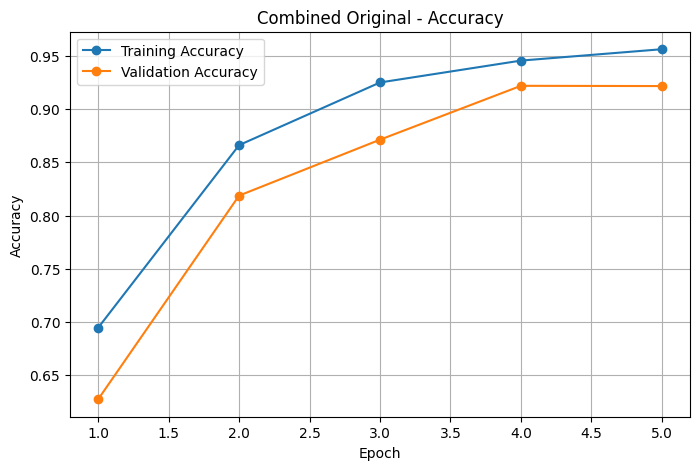

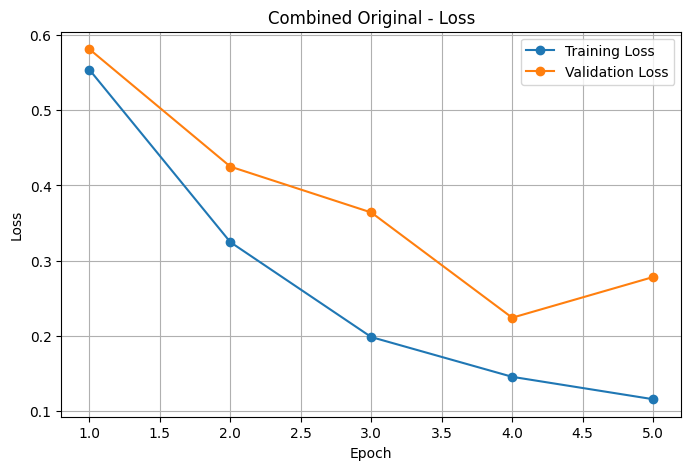

Graphs saved successfully!
Folder: /content/SmartCap_CNN/results/combined_graphs


In [107]:
import matplotlib.pyplot as plt
import os

# Create folder
graph_dir = "/content/SmartCap_CNN/results/combined_graphs"
os.makedirs(graph_dir, exist_ok=True)

epochs = range(1, len(history_combined_original.history["accuracy"]) + 1)

# Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_combined_original.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_combined_original.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Combined Original - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{graph_dir}/combined_original_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_combined_original.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history_combined_original.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Combined Original - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{graph_dir}/combined_original_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphs saved successfully!")
print("Folder:", graph_dir)

In [108]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tf.keras.utils.set_random_seed(42)

# CNN Architecture
model_combined_clahe = Sequential([
    Input(shape=(64, 64, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),

    GlobalAveragePooling2D(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model_combined_clahe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_combined_clahe.summary()

# Callbacks
early_stopping_clahe = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

checkpoint_clahe = ModelCheckpoint(
    "/content/combined_clahe_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Training
history_combined_clahe = model_combined_clahe.fit(
    train_ds_clahe,
    validation_data=val_ds_clahe,
    epochs=5,
    callbacks=[
        early_stopping_clahe,
        checkpoint_clahe
    ]
)

print("Combined CLAHE Training Completed!")

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_11     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.6918 - loss: 0.5278
Epoch 1: val_loss improved from None to 0.25674, saving model to /content/combined_clahe_best.keras

Epoch 1: finished saving model to /content/combined_clahe_best.keras
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 736s 336ms/step - accuracy: 0.8152 - loss: 0.3727 - val_accuracy: 0.8976 - val_loss: 0.2567
Epoch 2/5
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.9417 - loss: 0.1585
Epoch 2: val_loss improved from 0.25674 to 0.19708, saving model to /content/combined_clahe_best.keras

Epoch 2: finished saving model to /content/combined_clahe_best.keras
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 699s 324ms/step - accuracy: 0.9482 - loss: 0.1410 - val_accuracy: 0.9328 - val_loss: 0.1971
Epoch 3/5
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.9628 - loss: 0.1011
Epoch 3: val_loss improved from 0.19708 to 0.16283, saving model to /content/combined_clahe_best.keras

Epoch 3: finished saving model to /conte

In [109]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_clahe_source(model, dataframe, source_name):

    ds = create_dataset(dataframe, "clahe", training=False)

    y_true = dataframe["label"].astype(int).values
    y_prob = model.predict(ds, verbose=1).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    print("\n" + "=" * 55)
    print(f"{source_name} - VALIDATION RESULTS")
    print("=" * 55)

    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Balanced Accuracy:", balanced_accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("Macro F1:", f1_score(y_true, y_pred, average="macro"))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Closed", "Open"],
        zero_division=0
    ))

    return {
        "Source": source_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro")
    }


# Combined
result_combined_clahe = evaluate_clahe_source(
    model_combined_clahe,
    val_combined,
    "Combined CLAHE"
)

# MRL
mrl_val = val_combined[
    val_combined["dataset_source"] == "MRL"
].copy()

result_mrl_clahe = evaluate_clahe_source(
    model_combined_clahe,
    mrl_val,
    "MRL CLAHE"
)

# SmartCap
smartcap_val = val_combined[
    val_combined["dataset_source"] == "SmartCap"
].copy()

result_smartcap_clahe = evaluate_clahe_source(
    model_combined_clahe,
    smartcap_val,
    "SmartCap CLAHE"
)

# Summary
combined_clahe_results = pd.DataFrame([
    result_combined_clahe,
    result_mrl_clahe,
    result_smartcap_clahe
])

print("\nFINAL CLAHE SUMMARY")
display(combined_clahe_results)

536/536 ━━━━━━━━━━━━━━━━━━━━ 62s 115ms/step

Combined CLAHE - VALIDATION RESULTS
Accuracy: 0.9249343832020998
Balanced Accuracy: 0.9248982624146308
Precision: 0.9192034790569924
Recall: 0.9325438290955532
Macro F1: 0.9249235448508788

Confusion Matrix:
[[7826  706]
 [ 581 8032]]

Classification Report:
              precision    recall  f1-score   support

      Closed       0.93      0.92      0.92      8532
        Open       0.92      0.93      0.93      8613

    accuracy                           0.92     17145
   macro avg       0.93      0.92      0.92     17145
weighted avg       0.93      0.92      0.92     17145

532/532 ━━━━━━━━━━━━━━━━━━━━ 55s 103ms/step

MRL CLAHE - VALIDATION RESULTS
Accuracy: 0.9269454737956591
Balanced Accuracy: 0.926922129557021
Precision: 0.9232107644124812
Recall: 0.9320763555451458
Macro F1: 0.9269390833605298

Confusion Matrix:
[[7800  662]
 [ 580 7959]]

Classification Report:
              precision    recall  f1-score   support

      Closed    

,Source,Accuracy,Balanced Accuracy,Precision,Recall,Macro F1
0,Combined CLAHE,0.924934,0.924898,0.919203,0.932544,0.924924
1,MRL CLAHE,0.926945,0.926922,0.923211,0.932076,0.926939
2,SmartCap CLAHE,0.687500,0.678958,0.623932,0.986486,0.650240


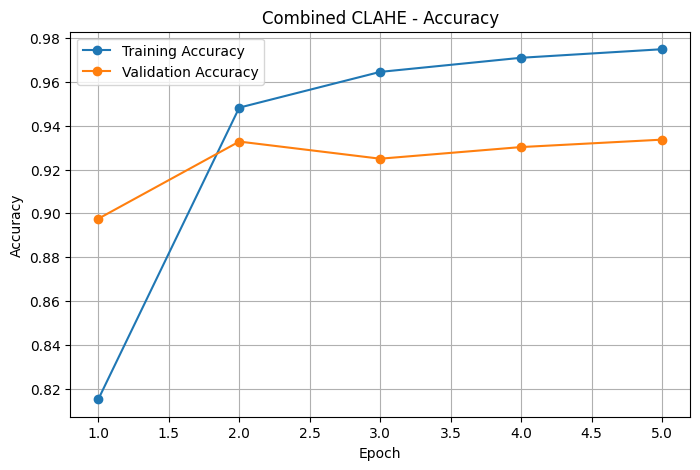

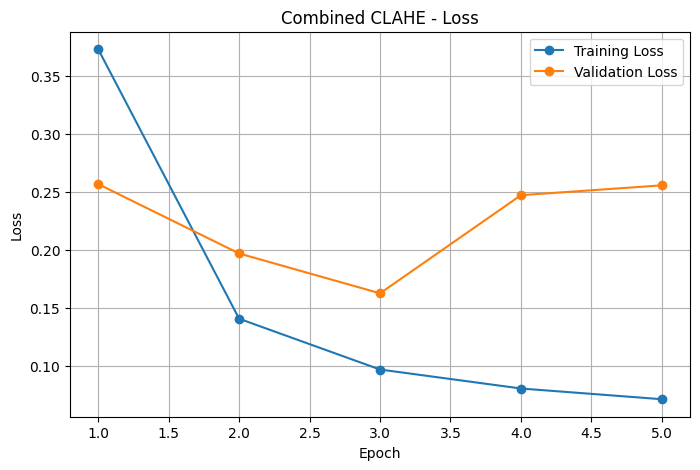

Combined CLAHE graphs saved successfully!


In [110]:
import matplotlib.pyplot as plt
import os

graph_dir = "/content/SmartCap_CNN/results/combined_graphs"
os.makedirs(graph_dir, exist_ok=True)

epochs = range(
    1,
    len(history_combined_clahe.history["accuracy"]) + 1
)

# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_combined_clahe.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_combined_clahe.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Combined CLAHE - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{graph_dir}/combined_clahe_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Loss
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_combined_clahe.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history_combined_clahe.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Combined CLAHE - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{graph_dir}/combined_clahe_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Combined CLAHE graphs saved successfully!")

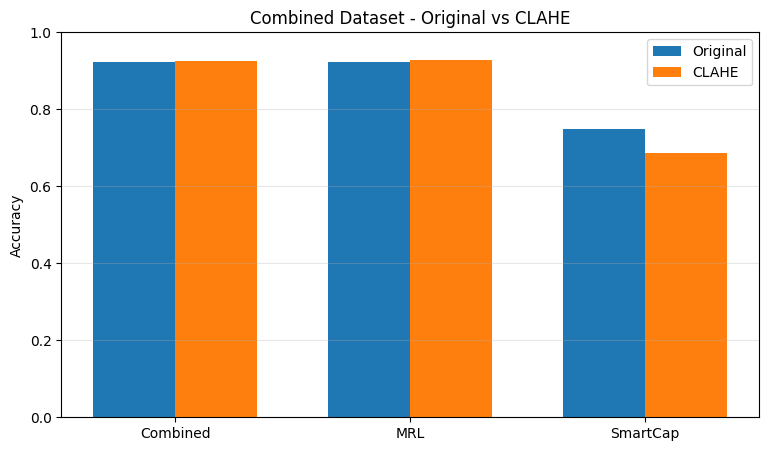

In [111]:
import matplotlib.pyplot as plt
import numpy as np

datasets = ["Combined", "MRL", "SmartCap"]

original_acc = [
    result_combined["Accuracy"],
    result_mrl["Accuracy"],
    result_smartcap["Accuracy"]
]

clahe_acc = [
    result_combined_clahe["Accuracy"],
    result_mrl_clahe["Accuracy"],
    result_smartcap_clahe["Accuracy"]
]

x = np.arange(len(datasets))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, original_acc, width, label="Original")
plt.bar(x + width/2, clahe_acc, width, label="CLAHE")

plt.xticks(x, datasets)
plt.ylabel("Accuracy")
plt.title("Combined Dataset - Original vs CLAHE")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    f"{graph_dir}/combined_original_vs_clahe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()